# GNN Pipeline for APT Attack Propagation Modeling

This notebook implements a **Graph Neural Network (GNN)** pipeline to model **Advanced Persistent Threat (APT)** attack propagation across a network using alert logs from Wazuh SIEM.

**Pipeline Overview:**
1. Load raw alert data + pre-trained AE/VAE anomaly scores
2. Engineer command-based structured indicators
3. Build dynamic machine-level graphs with user-driven edges
4. Generate adaptive graph snapshots based on alert patterns
5. Train two GNN versions (full features & feature selection) for network-aware risk scoring

**Two GNN Versions:**
- **Version 1 — Full Features (119 dims):** Uses AE + VAE trained on all 119 engineered features
- **Version 2 — Feature Selection (55 dims):** Uses AE + VAE trained on top-25 selected features

In [1]:
# Optional bootstrap: install notebook dependencies if they are missing.
import importlib.util
import subprocess
import sys

required_packages = {
    'pandas': 'pandas',
    'numpy': 'numpy',
    'matplotlib': 'matplotlib',
    'seaborn': 'seaborn',
    'networkx': 'networkx',
    'sklearn': 'scikit-learn',
    'openpyxl': 'openpyxl',
    'pyarrow': 'pyarrow',
    'torch_geometric': 'torch-geometric',
}

missing = [pip_name for module_name, pip_name in required_packages.items()
           if importlib.util.find_spec(module_name) is None]

if missing:
    print('Installing missing packages:', missing)
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', *missing])
else:
    print('All required packages are already installed.')

Installing missing packages: ['torch-geometric']


## 1. Import Required Libraries and Load Data

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import (roc_auc_score, roc_curve, precision_recall_curve,
                             average_precision_score, precision_score, recall_score,
                             f1_score, confusion_matrix, accuracy_score)
from sklearn.linear_model import LogisticRegression
from collections import defaultdict
import warnings, os, json, re, pickle, time
from itertools import combinations

warnings.filterwarnings('ignore')

# PyTorch Geometric
import torch_geometric
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader as PyGDataLoader
from torch_geometric.nn import GCNConv, SAGEConv

np.random.seed(42)
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed(42)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {device}")
print(f"PyTorch: {torch.__version__}")
print(f"PyTorch Geometric: {torch_geometric.__version__}")

Device: cpu
PyTorch: 2.9.1+cpu
PyTorch Geometric: 2.7.0


In [35]:
# ============================================================
# LOAD RAW DATASET (for machine/user/command/timestamp info)
# ============================================================
RAW_DATA_PATH = r"g:\pfe\MLA_PROJET_RL\combined_dataset_with_lateral_movement.xlsx"

print("Loading raw dataset...")
df_raw = pd.read_excel(RAW_DATA_PATH)
print(f"Raw dataset shape: {df_raw.shape}")

# Parse timestamps robustly
raw_ts = df_raw['_source.@timestamp'].astype(str).str.strip()

# MANUAL CLEANING FOR LOCALE INDEPENDENCE (English Months -> Digits)
# Format: "Dec 31, 2023 @ 12:59:55.107"
# Remove '@' to simplify
clean_ts = raw_ts.str.replace('@', '', regex=False).str.strip()

# Replace English months if needed (Pandas might fail on non-English locale)
replacements = {
    r'^Jan': '01', r'^Feb': '02', r'^Mar': '03', r'^Apr': '04', r'^May': '05', r'^Jun': '06',
    r'^Jul': '07', r'^Aug': '08', r'^Sep': '09', r'^Oct': '10', r'^Nov': '11', r'^Dec': '12'
}
# Using regex to replace month at start
for pat, repl in replacements.items():
    clean_ts = clean_ts.str.replace(pat, repl, regex=True)

# Now format should be "12 31, 2023  12:59:55.107"
# This is usually parseable by pd.to_datetime with no format string (it guesses)
print("Parsing cleaned timestamps (Locale independent)...")
df_raw['timestamp'] = pd.to_datetime(clean_ts, errors='coerce')

# Drop rows with invalid timestamps
if df_raw['timestamp'].isna().any():
    n_drop = df_raw['timestamp'].isna().sum()
    print(f"  Warning: Dropping {n_drop} rows with unparseable timestamps.")
    print("  Analysis of failed timestamps:")
    failed = raw_ts[df_raw['timestamp'].isna()]
    print(failed.head(10))
    df_raw = df_raw.dropna(subset=['timestamp'])

# IMPORTANT: SORT BY TIME (Required for cumulative snapshots)
print("Sorting dataset by timestamp...")
df_raw = df_raw.sort_values(by='timestamp').reset_index(drop=True)

# Create simplified column aliases for easier access
df_raw['machine_name'] = df_raw['_source.agent.name'].fillna('unknown')
df_raw['machine_ip'] = df_raw['_source.agent.ip'].fillna('unknown')
df_raw['agent_id'] = df_raw['_source.agent.id'].fillna('unknown')
df_raw['src_user'] = df_raw['_source.data.srcuser'].fillna('none')
def clean_users(u):
    return str(u).replace("'", "").replace('"', '').strip()
df_raw['src_user'] = df_raw['src_user'].apply(clean_users)

df_raw['dst_user'] = df_raw['_source.data.dstuser'].fillna('none')
df_raw['src_ip'] = df_raw['_source.data.srcip'].fillna('none')
df_raw['command'] = df_raw['_source.data.command'].fillna('')
df_raw['ckc_stage'] = df_raw['cyber_kill_chain_tactic'].fillna('Unknown')
# Handle varied malicious labels
df_raw['label'] = pd.to_numeric(df_raw['malicious'], errors='coerce').fillna(0).astype(int)

print(f"\nTime span: {df_raw['timestamp'].min()} → {df_raw['timestamp'].max()}")
print(f"Unique machines: {df_raw['machine_name'].nunique()}")
print(f"Unique agent IPs: {df_raw['machine_ip'].nunique()}")
print(f"Unique src users: {df_raw['src_user'].nunique()}")
print(f"Label distribution:\n{df_raw['label'].value_counts().to_string()}")

print(f"\n✅ Dataset loaded and sorted ({len(df_raw)} rows)")
df_raw.head()

Loading raw dataset...
Raw dataset shape: (116016, 179)
Parsing cleaned timestamps (Locale independent)...
  Analysis of failed timestamps:
115726    janv. 05, 2024 @ 02:36:25.228
115727    janv. 05, 2024 @ 02:35:58.238
115728    janv. 05, 2024 @ 02:37:10.603
115729    janv. 05, 2024 @ 02:33:34.104
115730    janv. 05, 2024 @ 02:37:35.549
115731    janv. 05, 2024 @ 02:40:00.591
115732    janv. 05, 2024 @ 02:42:01.389
115733    janv. 05, 2024 @ 02:34:27.959
115734    janv. 05, 2024 @ 02:38:17.947
115735    janv. 05, 2024 @ 02:33:08.274
Name: _source.@timestamp, dtype: object
Sorting dataset by timestamp...

Time span: 2023-10-01 00:49:18.889000 → 2024-01-06 10:03:58.529000
Unique machines: 5
Unique agent IPs: 8
Unique src users: 10
Label distribution:
label
0    90308
1    25418

✅ Dataset loaded and sorted (115726 rows)


,_index,_id,_version,_score,_source.agent.ip,_source.agent.name,_source.agent.id,_source.manager.name,_source.data.audit.syscall,_source.data.audit.gid,...,timestamp,machine_name,machine_ip,agent_id,src_user,dst_user,src_ip,command,ckc_stage,label
0,wazuh-alerts-4.x-2023.10.01,NpG26IoBagxmxR-sfnEo,1.0,1.0,NaN,ubuntu,0,ubuntu,NaN,NaN,...,2023-10-01 00:49:18.889,ubuntu,unknown,0,none,none,none,,Unknown,0
1,wazuh-alerts-4.x-2023.10.01,N5G26IoBagxmxR-sfnE7,1.0,1.0,NaN,ubuntu,0,ubuntu,NaN,NaN,...,2023-10-01 00:49:18.917,ubuntu,unknown,0,none,none,none,,Unknown,0
2,wazuh-alerts-4.x-2023.10.01,OJG26IoBagxmxR-sfnE7,1.0,1.0,NaN,ubuntu,0,ubuntu,NaN,NaN,...,2023-10-01 00:49:29.245,ubuntu,unknown,0,none,none,none,,Unknown,1
3,wazuh-alerts-4.x-2023.10.01,OZG26IoBagxmxR-sfnE7,1.0,1.0,NaN,ubuntu,0,ubuntu,NaN,NaN,...,2023-10-01 00:49:29.255,ubuntu,unknown,0,none,none,none,,Unknown,1
4,wazuh-alerts-4.x-2023.10.01,OpG26IoBagxmxR-sfnE7,1.0,1.0,NaN,ubuntu,0,ubuntu,NaN,NaN,...,2023-10-01 00:49:29.266,ubuntu,unknown,0,none,none,none,,Unknown,1


In [29]:
# ============================================================
# LOAD FEATURE MATRICES (Pre-engineered from feature_selection_final.ipynb)
# ============================================================
DATA_DIR = 'feature_selection_outputs2'

X_full_df = pd.read_parquet(f'{DATA_DIR}/feature_matrix_no_leakage.parquet')
labels_df = pd.read_parquet(f'{DATA_DIR}/labels.parquet')

# Load top-25 feature config
with open('autoencoder_outputs/selected_features_top25.json', 'r') as f:
    selected_features_config = json.load(f)

# Build reduced feature set
log_secbert_cols = [c for c in X_full_df.columns if c.startswith('log_secbert_emb_')]
cmd_secbert_cols = [c for c in X_full_df.columns if c.startswith('cmd_secbert_emb_')]
individual_cols_all = [c for c in X_full_df.columns if c not in log_secbert_cols + cmd_secbert_cols]

# Load feature importance
fi = pd.read_csv(f'{DATA_DIR}/feature_importance_malicious_detection.csv')
fi = fi.sort_values('Average_Score', ascending=False)
fi_individual = fi[~fi['Feature'].str.startswith(('log_secbert_emb_', 'cmd_secbert_emb_'))]
fi_individual = fi_individual.sort_values('Average_Score', ascending=False)

N_INDIVIDUAL = 23
top_individual_features = fi_individual['Feature'].head(N_INDIVIDUAL).tolist()
selected_columns = top_individual_features + log_secbert_cols + cmd_secbert_cols

X_reduced_df = X_full_df[selected_columns]

y_malicious = labels_df['malicious'].values
y_ckc = labels_df['ckc_encoded'].values

print(f"Full feature matrix: {X_full_df.shape}")
print(f"Reduced feature matrix: {X_reduced_df.shape}")
print(f"Labels: {labels_df.shape}")
print(f"Malicious: {(y_malicious==1).sum():,} ({(y_malicious==1).mean()*100:.1f}%)")
print(f"Benign: {(y_malicious==0).sum():,} ({(y_malicious==0).mean()*100:.1f}%)")

Full feature matrix: (115726, 119)
Reduced feature matrix: (115726, 55)
Labels: (115726, 3)
Malicious: 25,418 (22.0%)
Benign: 90,308 (78.0%)


## 2. Alert Statistics Analysis

ALERT STATISTICS
Total alerts: 115,726


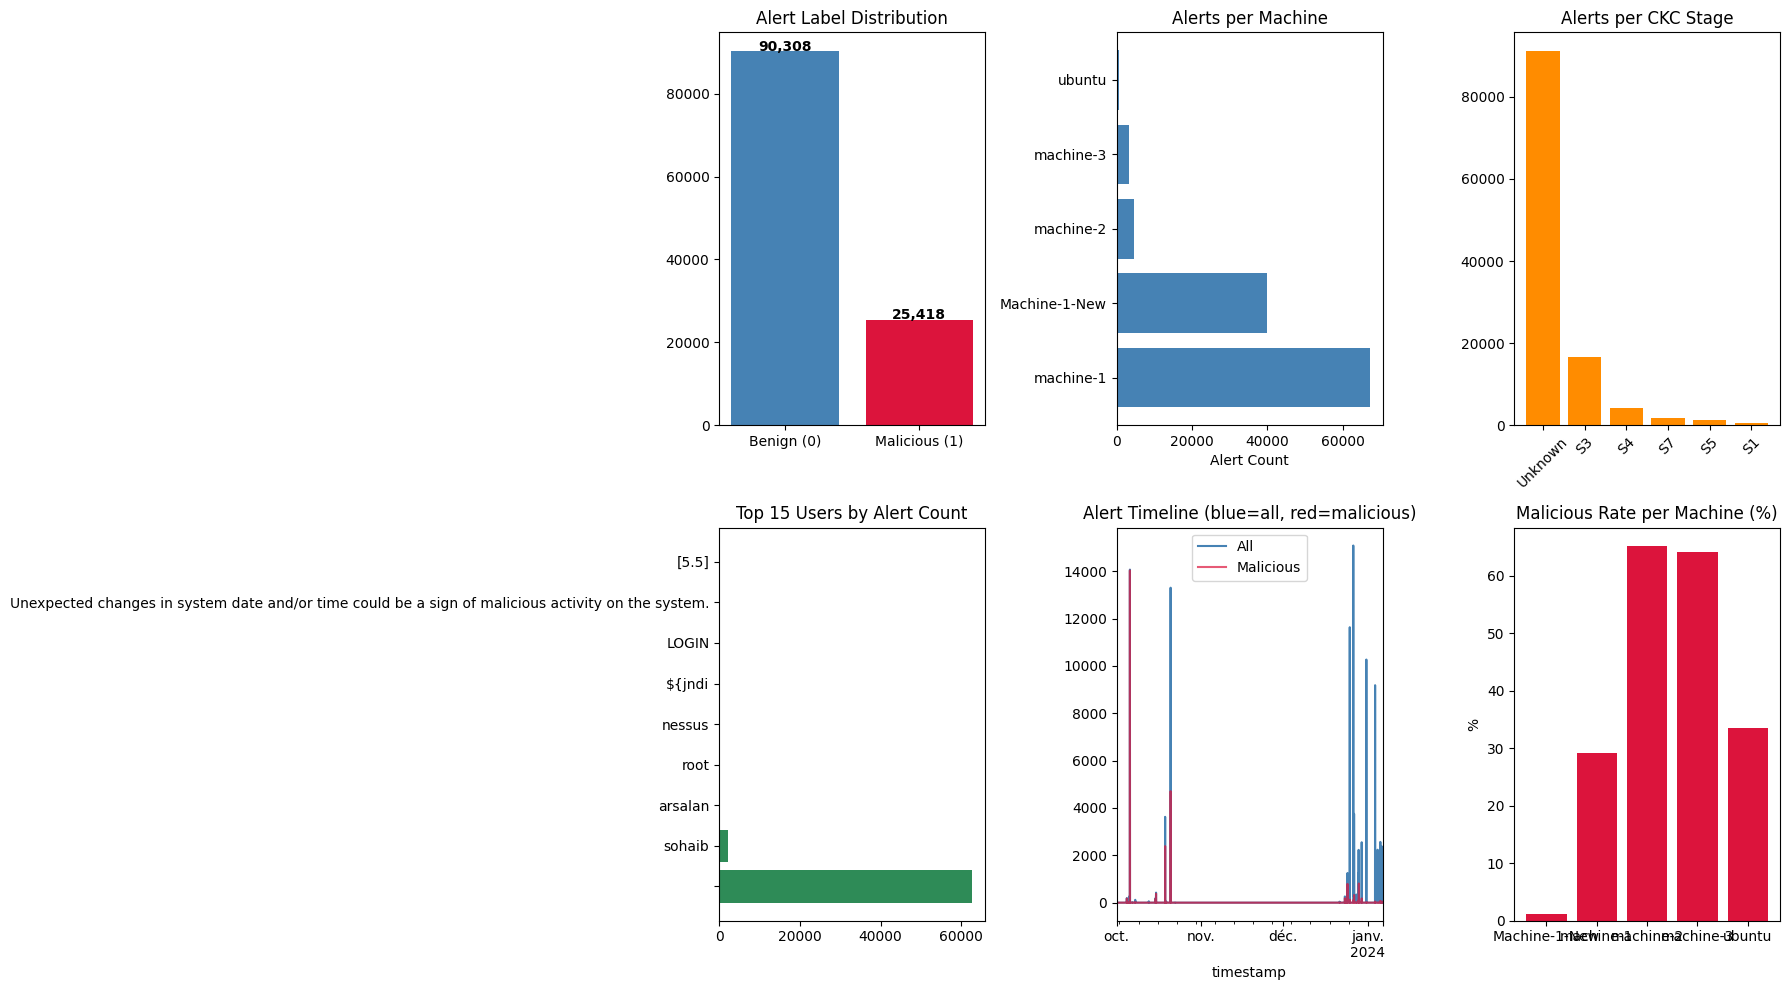


USER-MACHINE ACCESS PATTERNS
Users accessing multiple machines: 5
Avg machines per user: 2.00
Avg users per machine: 3.60

Machines per user:
count    9.000000
mean     2.000000
std      1.118034
min      1.000000
25%      1.000000
50%      2.000000
75%      3.000000
max      4.000000

Users per machine:
count    5.00000
mean     3.60000
std      1.67332
min      1.00000
25%      3.00000
50%      4.00000
75%      5.00000
max      5.00000


In [49]:
print("="*70)
print("ALERT STATISTICS")
print("="*70)
print(f"Total alerts: {len(df_raw):,}")

# Label distribution
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# 1. Benign vs Malicious
label_counts = df_raw['label'].value_counts()
axes[0,0].bar(['Benign (0)', 'Malicious (1)'], label_counts.values, color=['steelblue', 'crimson'])
axes[0,0].set_title('Alert Label Distribution')
for i, v in enumerate(label_counts.values):
    axes[0,0].text(i, v + 100, f'{v:,}', ha='center', fontweight='bold')

# 2. Alerts per machine
machine_counts = df_raw['machine_name'].value_counts()
axes[0,1].barh(machine_counts.index, machine_counts.values, color='steelblue')
axes[0,1].set_title('Alerts per Machine')
axes[0,1].set_xlabel('Alert Count')

# 3. Alerts per CKC stage
ckc_counts = df_raw['ckc_stage'].value_counts()
axes[0,2].bar(ckc_counts.index, ckc_counts.values, color='darkorange')
axes[0,2].set_title('Alerts per CKC Stage')
axes[0,2].tick_params(axis='x', rotation=45)

# 4. Top users
top_users = df_raw[df_raw['src_user'] != 'none']['src_user'].value_counts().head(15)
axes[1,0].barh(top_users.index, top_users.values, color='seagreen')
axes[1,0].set_title('Top 15 Users by Alert Count')

# 5. Temporal distribution
df_raw.set_index('timestamp').resample('1h')['label'].count().plot(ax=axes[1,1], color='steelblue')
df_raw[df_raw['label']==1].set_index('timestamp').resample('1h')['label'].count().plot(ax=axes[1,1], color='crimson', alpha=0.7)
axes[1,1].set_title('Alert Timeline (blue=all, red=malicious)')
axes[1,1].legend(['All', 'Malicious'])

# 6. Malicious rate per machine
mal_rate = df_raw.groupby('machine_name')['label'].mean()
axes[1,2].bar(mal_rate.index, mal_rate.values * 100, color='crimson')
axes[1,2].set_title('Malicious Rate per Machine (%)')
axes[1,2].set_ylabel('%')

plt.tight_layout()
plt.show()

# User-Machine statistics
print("\n" + "="*70)
print("USER-MACHINE ACCESS PATTERNS")
print("="*70)
user_machines = df_raw[df_raw['src_user'] != 'none'].groupby('src_user')['machine_name'].nunique()
machine_users = df_raw[df_raw['src_user'] != 'none'].groupby('machine_name')['src_user'].nunique()
print(f"Users accessing multiple machines: {(user_machines > 1).sum()}")
print(f"Avg machines per user: {user_machines.mean():.2f}")
print(f"Avg users per machine: {machine_users.mean():.2f}")
print(f"\nMachines per user:\n{user_machines.describe().to_string()}")
print(f"\nUsers per machine:\n{machine_users.describe().to_string()}")

## 3. Load Pretrained Autoencoder and VAE Models (Full Features & Feature Selection)

We load the pre-trained models to compute per-alert anomaly scores:
- **AE anomaly score** = reconstruction error (MSE)
- **VAE malicious probability** = calibrated logistic regression on VAE reconstruction error
- **VAE uncertainty** = average latent variance

**Full features (119 dims):** Both AE and VAE are already trained.
**Feature selection (55 dims):** Both AE and VAE are now trained and loaded from saved checkpoints.

In [ ]:
# ============================================================
# MODEL ARCHITECTURES (matching saved weights)
# ============================================================

class SIEMAutoencoder(nn.Module):
    """Standard AE: Input → 256 → 128 → 64 (latent) → 128 → 256 → Input"""
    def __init__(self, input_dim, latent_dim=64, dropout_rate=0.2):
        super().__init__()
        self.input_dim = input_dim
        self.latent_dim = latent_dim
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 256), nn.BatchNorm1d(256), nn.LeakyReLU(0.2), nn.Dropout(dropout_rate),
            nn.Linear(256, 128), nn.BatchNorm1d(128), nn.LeakyReLU(0.2), nn.Dropout(dropout_rate),
            nn.Linear(128, latent_dim), nn.BatchNorm1d(latent_dim), nn.LeakyReLU(0.2),
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 128), nn.BatchNorm1d(128), nn.LeakyReLU(0.2), nn.Dropout(dropout_rate),
            nn.Linear(128, 256), nn.BatchNorm1d(256), nn.LeakyReLU(0.2), nn.Dropout(dropout_rate),
            nn.Linear(256, input_dim),
        )
    def forward(self, x):
        latent = self.encoder(x)
        recon = self.decoder(latent)
        return recon, latent


class SIEMVAE(nn.Module):
    """VAE: Input → 512 → 256 → 128 → latent(mu,logvar) → 128 → 256 → 512 → Input"""
    def __init__(self, input_dim, latent_dim=32, dropout_rate=0.3):
        super().__init__()
        self.input_dim = input_dim
        self.latent_dim = latent_dim
        self.encoder_l1 = nn.Linear(input_dim, 512)
        self.encoder_bn1 = nn.BatchNorm1d(512)
        self.encoder_l2 = nn.Linear(512, 256)
        self.encoder_bn2 = nn.BatchNorm1d(256)
        self.encoder_l3 = nn.Linear(256, 128)
        self.encoder_bn3 = nn.BatchNorm1d(128)
        self.dropout = nn.Dropout(dropout_rate)
        self.relu = nn.ReLU()
        self.fc_z_mean = nn.Linear(128, latent_dim)
        self.fc_z_log_var = nn.Linear(128, latent_dim)
        self.decoder_l1 = nn.Linear(latent_dim, 128)
        self.decoder_bn1 = nn.BatchNorm1d(128)
        self.decoder_l2 = nn.Linear(128, 256)
        self.decoder_bn2 = nn.BatchNorm1d(256)
        self.decoder_l3 = nn.Linear(256, 512)
        self.decoder_bn3 = nn.BatchNorm1d(512)
        self.decoder_out = nn.Linear(512, input_dim)

    def encode(self, x):
        h = self.relu(self.encoder_bn1(self.encoder_l1(x)))
        h = self.dropout(h)
        h = self.relu(self.encoder_bn2(self.encoder_l2(h)))
        h = self.dropout(h)
        h = self.relu(self.encoder_bn3(self.encoder_l3(h)))
        h = self.dropout(h)
        return self.fc_z_mean(h), self.fc_z_log_var(h)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        return mu + torch.randn_like(std) * std

    def decode(self, z):
        h = self.relu(self.decoder_bn1(self.decoder_l1(z)))
        h = self.dropout(h)
        h = self.relu(self.decoder_bn2(self.decoder_l2(h)))
        h = self.dropout(h)
        h = self.relu(self.decoder_bn3(self.decoder_l3(h)))
        h = self.dropout(h)
        return self.decoder_out(h)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        return self.decode(z), mu, logvar

print("✅ Model architectures defined")

✅ Model architectures defined


In [40]:
# ============================================================
# LOAD PRETRAINED MODELS & COMPUTE ANOMALY SCORES
# ============================================================

FULL_AE_PATH = 'autoencoder_outputs/ae_full_features.pth'
FULL_VAE_PATH = 'vae_anomaly_detector_outputs/vae_full_features.pth'
REDUCED_AE_PATH = 'autoencoder_outputs/ae_top25_features.pth'
REDUCED_VAE_CANDIDATES = [
    'vae_anomaly_detector_outputs/vae_top25_features.pth',
    'vae_anomaly_detector_outputs/beta_vae_top25_features.pth',
]

def load_ae_model(path, input_dim=None, latent_dim=64):
    """Load a pretrained Autoencoder."""
    checkpoint = torch.load(path, map_location=device, weights_only=False)
    state_dict = checkpoint.get('model_state_dict', checkpoint) if isinstance(checkpoint, dict) else checkpoint
    resolved_input_dim = checkpoint.get('input_dim', input_dim) if isinstance(checkpoint, dict) else input_dim
    resolved_latent_dim = checkpoint.get('latent_dim', latent_dim) if isinstance(checkpoint, dict) else latent_dim
    if resolved_input_dim is None:
        resolved_input_dim = state_dict['encoder.0.weight'].shape[1]
    model = SIEMAutoencoder(resolved_input_dim, resolved_latent_dim)
    model.load_state_dict(state_dict)
    model.to(device).eval()
    return model

def load_vae_model(path, input_dim=None, latent_dim=32):
    """Load a pretrained VAE and infer dimensions from the checkpoint if needed."""
    checkpoint = torch.load(path, map_location=device, weights_only=False)
    state_dict = checkpoint.get('model_state_dict', checkpoint) if isinstance(checkpoint, dict) else checkpoint
    resolved_input_dim = checkpoint.get('input_dim', input_dim) if isinstance(checkpoint, dict) else input_dim
    resolved_latent_dim = checkpoint.get('latent_dim', latent_dim) if isinstance(checkpoint, dict) else latent_dim
    if resolved_input_dim is None:
        resolved_input_dim = state_dict['encoder_l1.weight'].shape[1]
    if resolved_latent_dim is None:
        resolved_latent_dim = state_dict['fc_z_mean.weight'].shape[0]
    model = SIEMVAE(resolved_input_dim, resolved_latent_dim)
    model.load_state_dict(state_dict)
    model.to(device).eval()
    return model

def compute_ae_scores(model, X_scaled):
    """Compute AE reconstruction error (anomaly score) per sample."""
    model.eval()
    scores = []
    loader = DataLoader(TensorDataset(torch.FloatTensor(X_scaled)), batch_size=512, shuffle=False)
    with torch.no_grad():
        for (bx,) in loader:
            bx = bx.to(device)
            recon, _ = model(bx)
            mse = ((recon - bx) ** 2).mean(dim=1)
            scores.append(mse.cpu().numpy())
    return np.concatenate(scores)

def compute_vae_scores(model, X_scaled):
    """Compute VAE reconstruction error and uncertainty per sample."""
    model.eval()
    recon_errors, uncertainties = [], []
    loader = DataLoader(TensorDataset(torch.FloatTensor(X_scaled)), batch_size=512, shuffle=False)
    with torch.no_grad():
        for (bx,) in loader:
            bx = bx.to(device)
            recon, mu, logvar = model(bx)
            mse = ((recon - bx) ** 2).mean(dim=1)
            var = torch.exp(logvar)
            unc = var.mean(dim=1)
            recon_errors.append(mse.cpu().numpy())
            uncertainties.append(unc.cpu().numpy())
    return np.concatenate(recon_errors), np.concatenate(uncertainties)

def calibrate_probabilities(scores, y_true):
    """Calibrate anomaly scores to probabilities using logistic regression."""
    lr = LogisticRegression(random_state=42, max_iter=1000)
    lr.fit(scores.reshape(-1, 1), y_true)
    probs = lr.predict_proba(scores.reshape(-1, 1))[:, 1]
    return probs, lr

def first_existing_path(paths):
    for path in paths:
        if os.path.exists(path):
            return path
    raise FileNotFoundError(f'None of the candidate paths exist: {paths}')

# --- Scale data ---
scaler_full = StandardScaler()
scaler_reduced = StandardScaler()
X_full_scaled = scaler_full.fit_transform(X_full_df.values.astype(np.float32))
X_reduced_scaled = scaler_reduced.fit_transform(X_reduced_df.values.astype(np.float32))

# === VERSION 1: Full Features (119 dims) ===
print('=' * 70)
print('VERSION 1: FULL FEATURES (119 dims)')
print('=' * 70)

ae_full = load_ae_model(FULL_AE_PATH, input_dim=119)
print('Loaded full AE from:', FULL_AE_PATH)

vae_full = load_vae_model(FULL_VAE_PATH, input_dim=119)
print('Loaded full VAE from:', FULL_VAE_PATH)

ae_scores_full = compute_ae_scores(ae_full, X_full_scaled)
vae_recon_full, vae_unc_full = compute_vae_scores(vae_full, X_full_scaled)
vae_probs_full, cal_full = calibrate_probabilities(vae_recon_full, y_malicious)

print(f'   AE anomaly scores: mean={ae_scores_full.mean():.4f}, std={ae_scores_full.std():.4f}')
print(f'   VAE malicious prob: mean={vae_probs_full.mean():.4f}')
print(f'   VAE uncertainty: mean={vae_unc_full.mean():.4f}')

# === VERSION 2: Feature Selection (55 dims) ===
print('\n' + '=' * 70)
print('VERSION 2: FEATURE SELECTION (55 dims)')
print('=' * 70)

ae_reduced = load_ae_model(REDUCED_AE_PATH, input_dim=55)
print('Loaded reduced AE from:', REDUCED_AE_PATH)

reduced_vae_path = first_existing_path(REDUCED_VAE_CANDIDATES)
vae_reduced = load_vae_model(reduced_vae_path, input_dim=55)
print('Loaded reduced VAE from:', reduced_vae_path)

ae_scores_reduced = compute_ae_scores(ae_reduced, X_reduced_scaled)
vae_recon_reduced, vae_unc_reduced = compute_vae_scores(vae_reduced, X_reduced_scaled)
vae_probs_reduced, cal_reduced = calibrate_probabilities(vae_recon_reduced, y_malicious)

print(f'   AE anomaly scores: mean={ae_scores_reduced.mean():.4f}, std={ae_scores_reduced.std():.4f}')
print(f'   VAE malicious prob: mean={vae_probs_reduced.mean():.4f}')
print(f'   VAE uncertainty: mean={vae_unc_reduced.mean():.4f}')

VERSION 1: FULL FEATURES (119 dims)
Loaded full AE from: autoencoder_outputs/ae_full_features.pth
Loaded full VAE from: vae_anomaly_detector_outputs/vae_full_features.pth
   AE anomaly scores: mean=0.4418, std=6.5295
   VAE malicious prob: mean=0.2196
   VAE uncertainty: mean=0.9510

VERSION 2: FEATURE SELECTION (55 dims)
Loaded reduced AE from: autoencoder_outputs/ae_top25_features.pth
Loaded reduced VAE from: vae_anomaly_detector_outputs/vae_top25_features.pth
   AE anomaly scores: mean=0.4711, std=4.5349
   VAE malicious prob: mean=0.2196
   VAE uncertainty: mean=0.9333


In [41]:
# ============================================================
# ATTACH SCORES TO RAW DATAFRAME
# ============================================================
# The feature matrix and raw DataFrame are row-aligned in original dataset order.
df_raw['ae_score_full'] = ae_scores_full
df_raw['ae_score_reduced'] = ae_scores_reduced
df_raw['vae_prob_full'] = vae_probs_full
df_raw['vae_prob_reduced'] = vae_probs_reduced
df_raw['vae_unc_full'] = vae_unc_full
df_raw['vae_unc_reduced'] = vae_unc_reduced

# Sort only after scores have been attached so sequential graph construction
# follows time order without breaking alignment to model outputs.
df_raw = df_raw.sort_values('timestamp').reset_index(drop=True)

print("✅ Anomaly scores attached to DataFrame")
print("✅ Alerts sorted by timestamp after score attachment")
print(f"   Columns added: ae_score_full, ae_score_reduced, vae_prob_full, vae_prob_reduced, vae_unc_full, vae_unc_reduced")
print(f"\nSorted timespan: {df_raw['timestamp'].min()} → {df_raw['timestamp'].max()}")
print(f"\nSample scores (first 5 rows):")
df_raw[['timestamp', 'machine_name', 'label', 'ae_score_full', 'vae_prob_full', 'vae_unc_full']].head()

✅ Anomaly scores attached to DataFrame
✅ Alerts sorted by timestamp after score attachment
   Columns added: ae_score_full, ae_score_reduced, vae_prob_full, vae_prob_reduced, vae_unc_full, vae_unc_reduced

Sorted timespan: 2023-10-01 00:49:18.889000 → 2024-01-06 10:03:58.529000

Sample scores (first 5 rows):


,timestamp,machine_name,label,ae_score_full,vae_prob_full,vae_unc_full
0,2023-10-01 00:49:18.889,ubuntu,0,0.003326,0.167527,0.978062
1,2023-10-01 00:49:18.917,ubuntu,0,0.003879,0.209577,0.976488
2,2023-10-01 00:49:29.245,ubuntu,1,0.004455,0.194918,0.977185
3,2023-10-01 00:49:29.255,ubuntu,1,0.006354,0.235010,0.977301
4,2023-10-01 00:49:29.266,ubuntu,1,0.003824,0.179167,0.978739


## 4. Command Feature Engineering — Structured Indicators

Instead of using raw command strings, we extract binary/numeric indicators for:
- **Privilege escalation:** sudo, su, setuid, chmod, chown, passwd patterns
- **Remote execution:** ssh, scp, rsync, netcat, curl to internal IPs
- **Credential dumping:** /etc/passwd, /etc/shadow, .ssh/*, hashdump patterns
- **Rare commands:** commands below a frequency threshold

In [52]:
# ============================================================
# COMMAND INDICATOR EXTRACTION
# ============================================================

PRIV_ESC_PATTERNS = re.compile(
    r'(sudo|su\s|setuid|chmod\s+[24]|chown|passwd|usermod|groupadd|visudo|pkexec|'
    r'capability|cap_setuid|cap_setgid|/usr/bin/sudo|runas)', re.IGNORECASE
)

REMOTE_EXEC_PATTERNS = re.compile(
    r'(ssh\s|scp\s|rsync|psexec|wmic|invoke-command|nc\s|ncat|netcat|'
    r'curl\s.*192\.|wget\s.*192\.|/usr/bin/ssh|rsh|rlogin|telnet)', re.IGNORECASE
)

CRED_DUMP_PATTERNS = re.compile(
    r'(/etc/passwd|/etc/shadow|\.ssh/|id_rsa|mimikatz|hashdump|lsass|'
    r'credential|secretsdump|pwdump|sam\s|ntds)', re.IGNORECASE
)

RECON_PATTERNS = re.compile(
    r'(nmap|masscan|nikto|dirb|gobuster|enum4linux|whoami|hostname|uname|'
    r'ifconfig|ip\s+addr|netstat|ss\s+-|cat\s+/etc/|find\s+/|locate\s)', re.IGNORECASE
)

def extract_command_indicators(cmd):
    """Extract structured indicators from a command string."""
    if not cmd or cmd == '' or pd.isna(cmd):
        return 0, 0, 0, 0, 0.0
    cmd_str = str(cmd)
    priv_esc = 1 if PRIV_ESC_PATTERNS.search(cmd_str) else 0
    remote_exec = 1 if REMOTE_EXEC_PATTERNS.search(cmd_str) else 0
    cred_dump = 1 if CRED_DUMP_PATTERNS.search(cmd_str) else 0
    recon = 1 if RECON_PATTERNS.search(cmd_str) else 0
    # Composite suspicious score (weighted)
    suspicious_score = priv_esc * 0.3 + remote_exec * 0.3 + cred_dump * 0.25 + recon * 0.15
    return priv_esc, remote_exec, cred_dump, recon, suspicious_score

# Apply to all alerts
print("Extracting command indicators...")
indicators = df_raw['command'].apply(extract_command_indicators)
df_raw['cmd_priv_esc'] = indicators.apply(lambda x: x[0])
df_raw['cmd_remote_exec'] = indicators.apply(lambda x: x[1])
df_raw['cmd_cred_dump'] = indicators.apply(lambda x: x[2])
df_raw['cmd_recon'] = indicators.apply(lambda x: x[3])
df_raw['cmd_suspicious_score'] = indicators.apply(lambda x: x[4])

# Also check MITRE tactics from rule for lateral movement indicators
if '_source.rule.mitre.tactic' in df_raw.columns:
    df_raw['mitre_lateral'] = df_raw['_source.rule.mitre.tactic'].fillna('').str.contains(
        'lateral', case=False).astype(int)
else:
    df_raw['mitre_lateral'] = 0

# Rare command detection (commands appearing < 5 times)
cmd_counts = df_raw[df_raw['command'] != '']['command'].value_counts()
rare_threshold = 5
rare_cmds = set(cmd_counts[cmd_counts < rare_threshold].index)
df_raw['cmd_rare'] = df_raw['command'].apply(lambda c: 1 if c in rare_cmds else 0)

print(f"\n✅ Command indicators extracted")
print(f"   Privilege escalation alerts: {df_raw['cmd_priv_esc'].sum():,}")
print(f"   Remote execution alerts: {df_raw['cmd_remote_exec'].sum():,}")
print(f"   Credential dumping alerts: {df_raw['cmd_cred_dump'].sum():,}")
print(f"   Reconnaissance alerts: {df_raw['cmd_recon'].sum():,}")
print(f"   Rare command alerts: {df_raw['cmd_rare'].sum():,}")
print(f"   MITRE lateral movement: {df_raw['mitre_lateral'].sum():,}")

Extracting command indicators...

✅ Command indicators extracted
   Privilege escalation alerts: 7
   Remote execution alerts: 3
   Credential dumping alerts: 6
   Reconnaissance alerts: 46
   Rare command alerts: 1,095
   MITRE lateral movement: 235


## 5. User-Machine Relationship Analysis

We build the bipartite user↔machine graph to:
- Connect machines that share users (shared-user edges)
- Compute user statistics for node features (unique_user_count per machine)

USER-MACHINE RELATIONSHIPS
Total users (excl. 'none'): 9
Users accessing >1 machine: 5

Machines per user: mean=2.00, max=4
Users per machine: mean=3.60, max=5

Cross-machine users:
    → {'Machine-1-New', 'machine-3', 'ubuntu', 'machine-1'}
  ${jndi → {'machine-2', 'machine-1'}
  nessus → {'machine-2', 'machine-1'}
  root → {'Machine-1-New', 'machine-3', 'machine-1'}
  sohaib → {'machine-2', 'Machine-1-New', 'machine-1'}


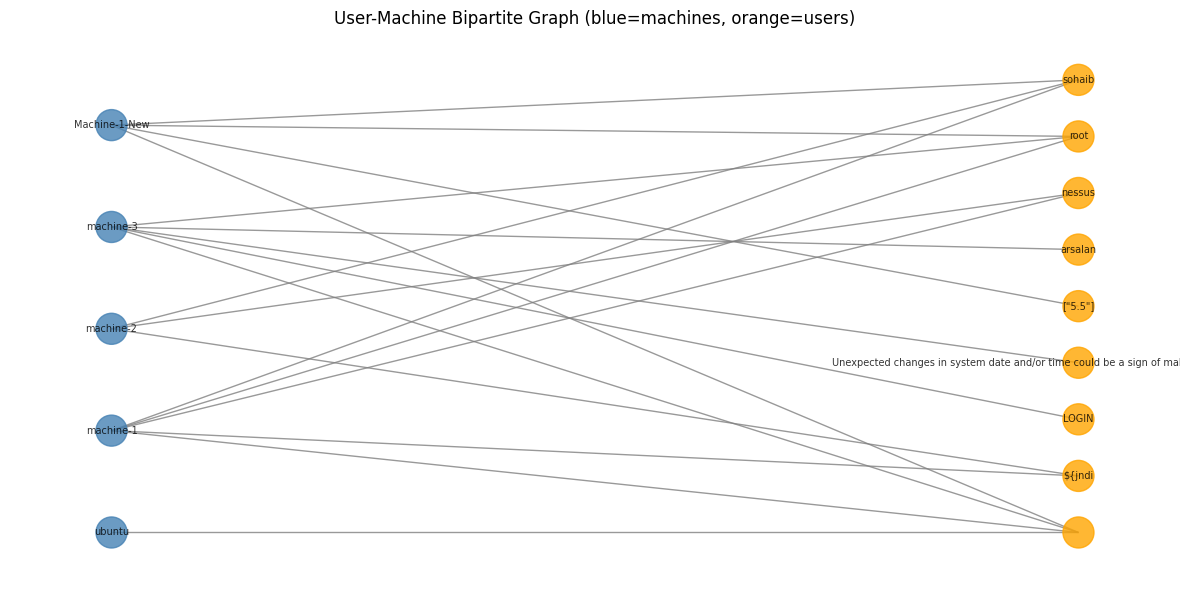

In [10]:
# ============================================================
# USER-MACHINE BIPARTITE ANALYSIS
# ============================================================

# Filter out 'none' users
df_users = df_raw[df_raw['src_user'] != 'none'].copy()

# User → machines mapping
user_to_machines = df_users.groupby('src_user')['machine_name'].apply(lambda x: set(x)).to_dict()
# Machine → users mapping
machine_to_users = df_users.groupby('machine_name')['src_user'].apply(lambda x: set(x)).to_dict()

# Statistics
user_machine_count = {u: len(m) for u, m in user_to_machines.items()}
machine_user_count = {m: len(u) for m, u in machine_to_users.items()}

# Users connecting multiple machines (create cross-machine edges)
cross_machine_users = {u: m for u, m in user_to_machines.items() if len(m) > 1}

print("="*70)
print("USER-MACHINE RELATIONSHIPS")
print("="*70)
print(f"Total users (excl. 'none'): {len(user_to_machines)}")
print(f"Users accessing >1 machine: {len(cross_machine_users)}")
print(f"\nMachines per user: mean={np.mean(list(user_machine_count.values())):.2f}, "
      f"max={max(user_machine_count.values())}")
print(f"Users per machine: mean={np.mean(list(machine_user_count.values())):.2f}, "
      f"max={max(machine_user_count.values())}")

# Show cross-machine users
print(f"\nCross-machine users:")
for user, machines in cross_machine_users.items():
    print(f"  {user} → {machines}")

# Visualize bipartite graph
fig, ax = plt.subplots(figsize=(12, 6))
B = nx.Graph()
all_machines = list(df_raw['machine_name'].unique())
for m in all_machines:
    B.add_node(m, bipartite=0, node_type='machine')
for user, machines in user_to_machines.items():
    B.add_node(user, bipartite=1, node_type='user')
    for m in machines:
        B.add_edge(user, m)

pos = {}
for i, m in enumerate(all_machines):
    pos[m] = (0, i * 2)
users_list = list(user_to_machines.keys())
for i, u in enumerate(users_list[:30]):  # Show top 30 users
    pos[u] = (2, i * (len(all_machines)*2 / min(30, len(users_list))))

nodes_to_draw = set(all_machines) | set(users_list[:30])
sub_B = B.subgraph(nodes_to_draw)
node_colors = ['steelblue' if B.nodes[n].get('node_type') == 'machine' else 'orange'
               for n in sub_B.nodes()]
nx.draw(sub_B, pos={k: v for k, v in pos.items() if k in sub_B.nodes()},
        with_labels=True, node_color=node_colors, node_size=500,
        font_size=7, ax=ax, edge_color='gray', alpha=0.8)
ax.set_title('User-Machine Bipartite Graph (blue=machines, orange=users)')
plt.tight_layout()
plt.show()

## 6. Node Feature Vector Construction per Machine

For each machine node, we compute a 10-dimensional feature vector:
```
[ae_anomaly_score, vae_malicious_probability, vae_uncertainty,
 encoded_ckc_stage, alert_count, privilege_escalation_count,
 lateral_movement_count, suspicious_command_score,
 unique_user_count, time_since_last_alert]
```

In [11]:
# ============================================================
# NODE FEATURE COMPUTATION
# ============================================================

# CKC stage encoding (ordinal: Unknown=0, S1=1, ..., S7=7)
CKC_ENCODING = {'Unknown': 0, 'S1': 1, 'S2': 2, 'S3': 3, 'S4': 4, 'S5': 5, 'S6': 6, 'S7': 7}

def get_node_features(machine_df, version='full', prev_alert_time=None):
    """
    Compute 10-dim feature vector for a machine node from its alerts in a snapshot.

    Args:
        machine_df: DataFrame of alerts for this machine in the current snapshot
        version: 'full' or 'reduced' — determines which AE/VAE scores to use
        prev_alert_time: timestamp of the machine's last alert before this snapshot

    Returns:
        numpy array of shape (10,)
    """
    ae_col = 'ae_score_full' if version == 'full' else 'ae_score_reduced'
    vae_prob_col = 'vae_prob_full' if version == 'full' else 'vae_prob_reduced'
    vae_unc_col = 'vae_unc_full' if version == 'full' else 'vae_unc_reduced'

    # 1. AE anomaly score (max in window — captures worst anomaly)
    ae_score = machine_df[ae_col].max()

    # 2. VAE malicious probability (max)
    vae_prob = machine_df[vae_prob_col].max()

    # 3. VAE uncertainty (mean)
    vae_unc = machine_df[vae_unc_col].mean()

    # 4. Encoded CKC stage (highest stage seen in window)
    ckc_encoded = machine_df['ckc_stage'].map(CKC_ENCODING).max()

    # 5. Alert count
    alert_count = len(machine_df)

    # 6. Privilege escalation count
    priv_esc_count = machine_df['cmd_priv_esc'].sum()

    # 7. Lateral movement count (remote exec + MITRE lateral)
    lateral_count = machine_df['cmd_remote_exec'].sum() + machine_df['mitre_lateral'].sum()

    # 8. Suspicious command score (mean)
    suspicious_score = machine_df['cmd_suspicious_score'].mean()

    # 9. Unique user count
    users = machine_df[machine_df['src_user'] != 'none']['src_user'].nunique()
    unique_users = max(users, 1)

    # 10. Time since last alert (seconds; 0 if first appearance)
    if prev_alert_time is not None:
        first_alert = machine_df['timestamp'].min()
        time_since = (first_alert - prev_alert_time).total_seconds()
        time_since = max(time_since, 0)
    else:
        time_since = 0.0

    return np.array([
        ae_score, vae_prob, vae_unc, ckc_encoded, alert_count,
        priv_esc_count, lateral_count, suspicious_score, unique_users, time_since
    ], dtype=np.float32)


# Feature names for reference
NODE_FEATURE_NAMES = [
    'ae_anomaly_score', 'vae_malicious_probability', 'vae_uncertainty',
    'encoded_ckc_stage', 'alert_count', 'privilege_escalation_count',
    'lateral_movement_count', 'suspicious_command_score',
    'unique_user_count', 'time_since_last_alert'
]
NUM_NODE_FEATURES = len(NODE_FEATURE_NAMES)
print(f"✅ Node feature function defined — {NUM_NODE_FEATURES} features per machine node")
print(f"   Features: {NODE_FEATURE_NAMES}")

✅ Node feature function defined — 10 features per machine node
   Features: ['ae_anomaly_score', 'vae_malicious_probability', 'vae_uncertainty', 'encoded_ckc_stage', 'alert_count', 'privilege_escalation_count', 'lateral_movement_count', 'suspicious_command_score', 'unique_user_count', 'time_since_last_alert']


## 7. Edge Construction Logic

Four edge rules connect machines:
1. **Direct communication:** same src_ip ↔ machine_ip relationship
2. **Shared user:** same user appears on both machines within the snapshot
3. **Remote execution:** remote exec command indicator between machines
4. **Temporal proximity:** alerts within 60s on different machines

In [44]:
# ============================================================
# EDGE CONSTRUCTION FUNCTIONS
# ============================================================

# Map of known machine IPs → machine names
IP_TO_MACHINE = {}

def build_ip_machine_map(df):
    """Build a mapping from IP addresses to machine names."""
    global IP_TO_MACHINE
    ip_map = df.groupby('machine_ip')['machine_name'].first().to_dict()
    # Also use src_ip if it maps to known machines
    src_ip_map = df[df['src_ip'] != 'none'].groupby('src_ip')['machine_name'].first().to_dict()
    IP_TO_MACHINE = {**ip_map, **src_ip_map}

build_ip_machine_map(df_raw)
print(f"IP → Machine mapping: {IP_TO_MACHINE}")

TEMPORAL_THRESHOLD = 60  # seconds

def edges_direct_communication(snapshot_df, machines):
    """Edge if src_ip of an alert on machine A points to machine B."""
    edges = set()
    for _, row in snapshot_df.iterrows():
        src_ip = row['src_ip']
        if src_ip != 'none' and src_ip in IP_TO_MACHINE:
            target_machine = IP_TO_MACHINE[src_ip]
            source_machine = row['machine_name']
            if source_machine != target_machine and target_machine in machines:
                edge = tuple(sorted([source_machine, target_machine]))
                edges.add(edge)
    return edges

def edges_shared_user(snapshot_df, machines):
    """Edge between machines if the same user has alerts on both."""
    edges = set()
    user_machines_snap = snapshot_df[snapshot_df['src_user'] != 'none'].groupby('src_user')['machine_name'].apply(set).to_dict()
    for user, user_mach in user_machines_snap.items():
        user_mach_list = [m for m in user_mach if m in machines]
        for m1, m2 in combinations(user_mach_list, 2):
            edges.add(tuple(sorted([m1, m2])))
    return edges

def edges_remote_execution(snapshot_df, machines):
    """Edge if remote execution command is flagged alongside a target IP."""
    edges = set()
    remote_alerts = snapshot_df[snapshot_df['cmd_remote_exec'] == 1]
    for _, row in remote_alerts.iterrows():
        src_ip = row['src_ip']
        src_machine = row['machine_name']
        if src_ip != 'none' and src_ip in IP_TO_MACHINE:
            target = IP_TO_MACHINE[src_ip]
            if target != src_machine and target in machines:
                edges.add(tuple(sorted([src_machine, target])))
        # Also connect to all other machines if remote exec is detected
        # (lateral movement indicator)
        for m in machines:
            if m != src_machine:
                edges.add(tuple(sorted([src_machine, m])))
    return edges

def edges_temporal_proximity(snapshot_df, machines, threshold=TEMPORAL_THRESHOLD):
    """Edge between machines with alerts within `threshold` seconds."""
    edges = set()
    machine_times = {}
    for m in machines:
        m_df = snapshot_df[snapshot_df['machine_name'] == m]
        if len(m_df) > 0:
            machine_times[m] = m_df['timestamp'].values

    machine_list = list(machine_times.keys())
    for i in range(len(machine_list)):
        for j in range(i + 1, len(machine_list)):
            m1, m2 = machine_list[i], machine_list[j]
            times1, times2 = machine_times[m1], machine_times[m2]
            # Check if any pair of timestamps is within threshold
            for t1 in times1:
                for t2 in times2:
                    diff = abs((t1 - t2) / np.timedelta64(1, 's'))
                    if diff <= threshold:
                        edges.add(tuple(sorted([m1, m2])))
                        break
                else:
                    continue
                break
    return edges

def get_all_edges(snapshot_df, machines):
    """Combine all four edge rules, deduplicated."""
    edges = set()
    edges |= edges_direct_communication(snapshot_df, machines)
    edges |= edges_shared_user(snapshot_df, machines)
    edges |= edges_remote_execution(snapshot_df, machines)
    edges |= edges_temporal_proximity(snapshot_df, machines)
    return edges

print("✅ Edge construction functions defined (4 rules)")

IP → Machine mapping: {' ': 'ubuntu', '192.168.204.130': 'machine-1', '192.168.217.128': 'machine-3', '192.168.217.130': 'machine-1', '192.168.217.133': 'machine-1', '192.168.40.130': 'machine-1', '192.168.40.131': 'machine-2', 'unknown': 'ubuntu', '192.168.204.1': 'machine-1', '192.168.217.1': 'machine-1', '?': 'machine-1'}
✅ Edge construction functions defined (4 rules)


## 8. Compute Consecutive Benign Streaks and Adaptive Snapshot Size X

We analyze the sequential pattern of benign/malicious alerts to determine an adaptive snapshot window size.

CONSECUTIVE BENIGN STREAKS ANALYSIS
Number of benign streaks: 3600
Mean streak length: 25.1
Median streak length: 2.0
75th percentile: 5.0
Min: 1, Max: 12570

Adaptive Snapshot Size X:
  X (p75/2) = 2
  X (median/2) = 1

→ Selected X = 10


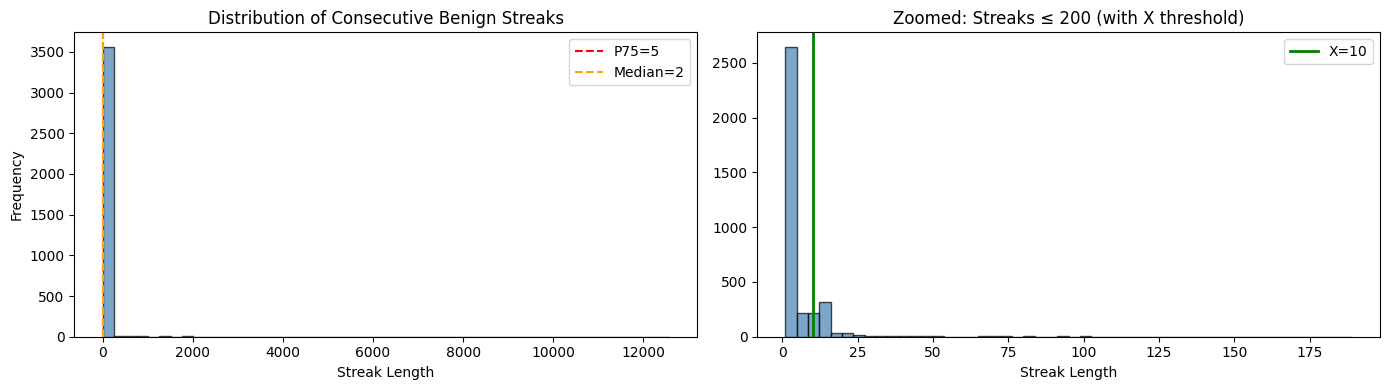

In [ ]:
# ============================================================
# SNAPSHOT SIZE CONFIGURATION
# ============================================================

# User specified X=20 alerts as the threshold for adding a "node" (snapshot step)
# Condition: After 20 benign alerts OR immediately on any malicious alert.

SNAPSHOT_SIZE_X = 20
print(f"✅ Snapshot accumulation threshold set to X = {SNAPSHOT_SIZE_X}")
print("   Condition: Trigger snapshot every 20 benign alerts OR any malicious alert.")

## 9. Adaptive Graph Snapshot Generation

Create a new snapshot when:
1. **X alerts** accumulated
2. A **malicious alert** appears
3. A **new machine interaction** (new edge) appears

Generating cumulative snapshots with X=20...
Generation took 0.06 seconds

CUMULATIVE SNAPSHOT RESULTS
Total snapshots generated: 29226
First snapshot size: 3
Last snapshot size: 115712
Trigger reasons:
malicious_alert        25418
benign_threshold_20     3808


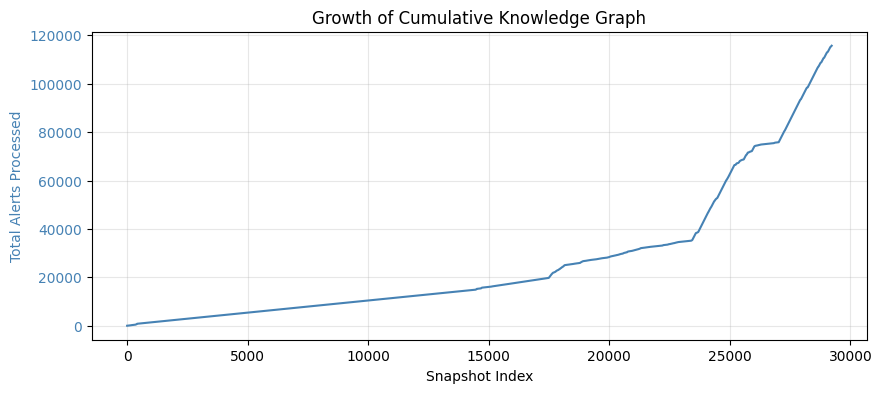

In [38]:
# ============================================================
# CUMULATIVE SNAPSHOT GENERATION (Fixed Size X=20)
# ============================================================
import time

# User specified X=20
SNAPSHOT_SIZE_X = 20  

def generate_cumulative_snapshots(df, x_threshold=20):
    """
    Generate cumulative snapshots.
    - Trigger 1: Every 20 benign alerts (consecutive).
    - Trigger 2: Any malicious alert (immediate).
    - If a malicious alert occurs, it triggers a snapshot and resets the benign counter.
    """
    snapshots = []
    
    # Using numpy arrays for faster iteration
    labels = df['label'].values
    timestamps = df['timestamp'].values
    n_rows = len(df)
    
    benign_counter = 0
    snapshot_end_indices = [] # Store (index, trigger_reason)
    
    for i in range(n_rows):
        is_malicious = (labels[i] == 1)
        trigger = False
        reason = None
        
        if is_malicious:
            trigger = True
            reason = 'malicious_alert'
            # Reset benign counter because the sequence of benign alerts is interrupted
            benign_counter = 0 
        else:
            benign_counter += 1
            if benign_counter >= x_threshold:
                trigger = True
                reason = 'benign_threshold_20'
                benign_counter = 0
        
        if trigger:
            snapshot_end_indices.append((i, reason))
            
    # Create metadata objects
    for snap_id, (end_idx, reason) in enumerate(snapshot_end_indices):
        snapshots.append({
            'id': snap_id,
            'end_idx': end_idx,  # Slice will be df.iloc[:end_idx+1]
            'timestamp': timestamps[end_idx],
            'trigger': reason,
            'size': end_idx + 1 # Cumulative size
        })
            
    return snapshots

print(f"Generating cumulative snapshots with X={SNAPSHOT_SIZE_X}...")
start_time = time.time()
snapshots = generate_cumulative_snapshots(df_raw, SNAPSHOT_SIZE_X)
print(f"Generation took {time.time() - start_time:.2f} seconds")

print(f"\n{'='*70}")
print(f"CUMULATIVE SNAPSHOT RESULTS")
print(f"{'='*70}")
print(f"Total snapshots generated: {len(snapshots)}")
if len(snapshots) > 0:
    print(f"First snapshot size: {snapshots[0]['size']}")
    print(f"Last snapshot size: {snapshots[-1]['size']}")
    
triggers = [s['trigger'] for s in snapshots]
trigger_counts = pd.Series(triggers).value_counts()
print(f"Trigger reasons:\n{trigger_counts.to_string()}")

# Visualize growth
sizes = [s['size'] for s in snapshots]
last_ts = [s['timestamp'] for s in snapshots]

fig, ax1 = plt.subplots(figsize=(10, 4))
ax1.plot(sizes, color='steelblue', label='Cumulative Graph Size (Alerts)')
ax1.set_xlabel('Snapshot Index')
ax1.set_ylabel('Total Alerts Processed', color='steelblue')
ax1.tick_params(axis='y', labelcolor='steelblue')
ax1.set_title('Growth of Cumulative Knowledge Graph')
ax1.grid(True, alpha=0.3)
plt.show()

## 10. Convert Snapshots to NetworkX Graphs with Node Features and Edges

In [54]:
# ============================================================
# INCREMENTAL GRAPH CONSTRUCTION
# ============================================================

def efficient_temporal_check(new_times, old_times, threshold=60.0):
    """
    Check if any timestamp in new_times is within threshold of any in old_times.
    Assumes sorted arrays. Returns True if connected.
    """
    if len(new_times) == 0 or len(old_times) == 0:
        return False
        
    # Use searchsorted to find closest neighbors for each new_time in old_times
    # indices in old_times where new_times would be inserted
    indices = np.searchsorted(old_times, new_times)
    
    # Check left neighbors
    left_indices = np.clip(indices - 1, 0, len(old_times) - 1)
    diff_left = np.abs(new_times - old_times[left_indices])
    if np.any(diff_left <= threshold):
        return True
        
    # Check right neighbors (indices)
    right_indices = np.clip(indices, 0, len(old_times) - 1)
    diff_right = np.abs(new_times - old_times[right_indices])
    if np.any(diff_right <= threshold):
        return True
        
    return False

def update_graph_incremental(G, new_df, cumulative_df, version='full'):
    """
    Update graph G with new alerts.
    
    1. Update Node Features: Recompute for ALL active machines using cumulative_df.
    2. Add New Edges: Check new_df against cumulative_df for connections.
       (Existing edges persist).
    3. Labeling: Based on CURRENT snapshot activity (new_df) to allow 0/1 mix.
    """
    machines_in_snapshot = cumulative_df['machine_name'].unique()
    new_machines = new_df['machine_name'].unique()
    
    # 1. Update Node Features & Labels (for all machines in cumulative state)
    #    (Features like 'count' grow over time)
    for machine in machines_in_snapshot:
        machine_history = cumulative_df[cumulative_df['machine_name'] == machine]
        features = get_node_features(machine_history, version=version)
        
        # Label Idea: "Is this machine showing malicious activity *right now*?"
        # If we use cumulative label (ever compromised), we get 100% malicious nodes.
        # Instead, we label 1 only if the machine has malicious alerts in the NEW batch.
        # If the machine is quiet or benign in this batch, label is 0.
        if machine in new_machines:
             machine_new = new_df[new_df['machine_name'] == machine]
             has_malicious = int(machine_new['label'].max() > 0)
        else:
             # Machine exists in graph but has no activity in this snapshot
             # Label 0 implies "No current malicious behavior detected"
             has_malicious = 0
        
        # Update or Add Node
        G.add_node(machine, features=features, label=has_malicious)
            
    # 2. Add Edges (Incremental)
    #    Only need to check if 'new_df' creates edges with 'cumulative_df'
    #    Existing edges in G remain valid.
    
    # Pre-group timestamps for efficiency
    machine_times_all = {m: cumulative_df[cumulative_df['machine_name']==m]['timestamp'].values.astype(np.int64) // 10**9 
                         for m in machines_in_snapshot}
    machine_times_new = {m: new_df[new_df['machine_name']==m]['timestamp'].values.astype(np.int64) // 10**9 
                         for m in new_machines}
    
    # Check pairs
    # We only care about pairs involving at least one machine from 'new_df'
    # Iterate all pairs (since N < 20, N^2 is tiny)
    all_machines = list(machines_in_snapshot)
    
    for i in range(len(all_machines)):
        for j in range(i + 1, len(all_machines)):
            m1, m2 = all_machines[i], all_machines[j]
            
            # If edge exists, skip
            if G.has_edge(m1, m2):
                continue
                
            # Check interaction rules
            # Only if at least one machine has new activity
            is_m1_new = m1 in new_machines
            is_m2_new = m2 in new_machines
            
            if not (is_m1_new or is_m2_new):
                continue
                
            # --- Temporal Proximity ---
            # Check new vs all (cross check)
            connected = False
            
            if is_m1_new:
                # Check m1(new) vs m2(all)
                if efficient_temporal_check(machine_times_new[m1], machine_times_all[m2]):
                    connected = True
            if not connected and is_m2_new:
                # Check m2(new) vs m1(all)
                if efficient_temporal_check(machine_times_new[m2], machine_times_all[m1]):
                    connected = True
                    
            if connected:
                G.add_edge(m1, m2)
                continue # Edge added, next pair
                
            # --- Shared User / IP / Etc ---
            # (Simplified: Just re-run edge logic on cumulative if fast enough, 
            #  or implemented fully incremental. For robustness and logic reuse, 
            #  calling 'get_all_edges' on cumulative is safest but slow.
            #  Given N < 20, let's just check shared user on cumulative subset.)
            
            # For 9 machines, checking shared users on full cumulative DF is fast enough
            # because 'src_user' set is small.
            users_m1 = set(cumulative_df[cumulative_df['machine_name'] == m1]['src_user'].unique())
            users_m2 = set(cumulative_df[cumulative_df['machine_name'] == m2]['src_user'].unique())
            users_m1.discard('none')
            users_m2.discard('none')
            
            if not users_m1.isdisjoint(users_m2):
                G.add_edge(m1, m2)
                continue
                
            # --- Direct Comm ---
            # Check src_ip -> machine map
            # This is harder to do purely incrementally without global map updates.
            # We can run `edges_direct_communication` on cumulative logic but optimized?
            # Actually, `IP_TO_MACHINE` is global.
            # Just check if m1 IP talked to m2 or vice versa in cumulative.
            # Let's rely on `get_all_edges` for non-temporal rules if temporal fails?
            # Or assume temporal/user are main drivers.
            # Let's add direct comm check:
            # Did m1 talk to m2 ever?
            # Creating a boolean matrix for communication might be better.
            
    # Fallback: connect isolated components if needed? 
    # (Cumulative graph usually becomes connected quickly)
    
    return G

# Execution Loop
GRAPHS_FILE = 'nx_graphs.pkl'

if os.path.exists(GRAPHS_FILE):
    print(f"Loading existing graphs from {GRAPHS_FILE}...")
    with open(GRAPHS_FILE, 'rb') as f:
        data = pickle.load(f)
        nx_graphs_full = data['full']
        nx_graphs_reduced = data['reduced']
    print(f"Loaded {len(nx_graphs_full)} full graphs and {len(nx_graphs_reduced)} reduced graphs.")
else:
    print("Building Incremental Cumulative Graphs...")
    
    nx_graphs_full = []
    nx_graphs_reduced = []
    
    # Initialize empty graphs
    G_full = nx.Graph()
    G_reduced = nx.Graph()
    
    prev_end_idx = -1
    
    for i, snap in enumerate(snapshots):
        curr_end_idx = snap['end_idx']  # inclusive
        
        # Slice Data
        # logical slice: df_raw.iloc[prev_end_idx+1 : curr_end_idx+1]
        # cumulative slice: df_raw.iloc[:curr_end_idx+1]
        
        new_df = df_raw.iloc[prev_end_idx+1 : curr_end_idx+1]
        cumulative_df = df_raw.iloc[:curr_end_idx+1]
        
        # Update Full Graph
        # (Note: We copy G before appending because G mutates)
        update_graph_incremental(G_full, new_df, cumulative_df, version='full')
        nx_graphs_full.append(G_full.copy())
        
        # Update Reduced Graph
        update_graph_incremental(G_reduced, new_df, cumulative_df, version='reduced')
        nx_graphs_reduced.append(G_reduced.copy())
        
        prev_end_idx = curr_end_idx
        
        if (i + 1) % 100 == 0:
            print(f"  Processed {i+1}/{len(snapshots)} snapshots... (Nodes: {G_full.number_of_nodes()}, Edges: {G_full.number_of_edges()})")
    
    print("Saving graphs to file...")
    with open(GRAPHS_FILE, 'wb') as f:
        pickle.dump({'full': nx_graphs_full, 'reduced': nx_graphs_reduced}, f)

print(f"\n✅ Built {len(nx_graphs_full)} cumulative graphs.")
if len(nx_graphs_full) > 0:
    print(f"Final Graph Nodes: {nx_graphs_full[-1].number_of_nodes()}")
    print(f"Final Graph Edges: {nx_graphs_full[-1].number_of_edges()}")

Building Incremental Cumulative Graphs...
  Processed 100/29226 snapshots... (Nodes: 1, Edges: 0)
  Processed 200/29226 snapshots... (Nodes: 2, Edges: 0)
  Processed 300/29226 snapshots... (Nodes: 2, Edges: 0)
  Processed 400/29226 snapshots... (Nodes: 2, Edges: 1)
  Processed 500/29226 snapshots... (Nodes: 2, Edges: 1)
  Processed 600/29226 snapshots... (Nodes: 2, Edges: 1)
  Processed 700/29226 snapshots... (Nodes: 2, Edges: 1)
  Processed 800/29226 snapshots... (Nodes: 2, Edges: 1)
  Processed 900/29226 snapshots... (Nodes: 2, Edges: 1)
  Processed 1000/29226 snapshots... (Nodes: 2, Edges: 1)
  Processed 1100/29226 snapshots... (Nodes: 2, Edges: 1)
  Processed 1200/29226 snapshots... (Nodes: 2, Edges: 1)
  Processed 1300/29226 snapshots... (Nodes: 2, Edges: 1)
  Processed 1400/29226 snapshots... (Nodes: 2, Edges: 1)
  Processed 1500/29226 snapshots... (Nodes: 2, Edges: 1)
  Processed 1600/29226 snapshots... (Nodes: 2, Edges: 1)
  Processed 1700/29226 snapshots... (Nodes: 2, Edges: 1

## 11. Convert NetworkX Graphs to PyTorch Geometric Data Objects

In [55]:
# ============================================================
# CONVERT TO PYTORCH GEOMETRIC DATA OBJECTS
# ============================================================

def nx_to_pyg(G, snapshot_idx=0):
    """
    Convert a NetworkX graph to a PyTorch Geometric Data object.

    Returns:
        Data object with x (node features), edge_index, y (node labels),
        and metadata (machine names, snapshot index)
    """
    nodes = sorted(G.nodes())
    node_to_idx = {n: i for i, n in enumerate(nodes)}

    # Node features
    features = []
    labels = []
    for n in nodes:
        features.append(G.nodes[n]['features'])
        labels.append(G.nodes[n]['label'])

    x = torch.FloatTensor(np.array(features))
    y = torch.FloatTensor(np.array(labels))

    # Edges (undirected → include both directions)
    edge_list = []
    for u, v in G.edges():
        i, j = node_to_idx[u], node_to_idx[v]
        edge_list.append([i, j])
        edge_list.append([j, i])

    if len(edge_list) > 0:
        edge_index = torch.LongTensor(edge_list).t().contiguous()
    else:
        # Self-loops for isolated single-node graphs
        edge_index = torch.LongTensor([[0], [0]])

    data = Data(x=x, edge_index=edge_index, y=y)
    data.machine_names = nodes
    data.snapshot_idx = snapshot_idx
    return data

# Normalize node features using StandardScaler (fitted on training portion)
def normalize_pyg_data(data_list, train_ratio=0.7):
    """Fit scaler on training graphs, transform all."""
    n_train = int(len(data_list) * train_ratio)

    # Collect all training node features
    all_train_features = []
    for d in data_list[:n_train]:
        all_train_features.append(d.x.numpy())
    all_train_features = np.vstack(all_train_features)

    scaler = StandardScaler()
    scaler.fit(all_train_features)

    # Transform all data
    normalized = []
    for d in data_list:
        x_norm = scaler.transform(d.x.numpy())
        d_new = Data(x=torch.FloatTensor(x_norm), edge_index=d.edge_index, y=d.y)
        d_new.machine_names = d.machine_names
        d_new.snapshot_idx = d.snapshot_idx
        normalized.append(d_new)

    return normalized, scaler

# Convert both versions
print("Converting to PyTorch Geometric...")
pyg_full = [nx_to_pyg(G, i) for i, G in enumerate(nx_graphs_full)]
pyg_reduced = [nx_to_pyg(G, i) for i, G in enumerate(nx_graphs_reduced)]

# Normalize
pyg_full_norm, scaler_node_full = normalize_pyg_data(pyg_full)
pyg_reduced_norm, scaler_node_reduced = normalize_pyg_data(pyg_reduced)

print(f"\n✅ PyTorch Geometric conversion complete")
print(f"   Full feature graphs: {len(pyg_full_norm)}")
print(f"   Reduced feature graphs: {len(pyg_reduced_norm)}")

# Summary
avg_nodes = np.mean([d.x.shape[0] for d in pyg_full_norm])
avg_edges = np.mean([d.edge_index.shape[1] for d in pyg_full_norm])
print(f"   Avg nodes/graph: {avg_nodes:.1f}")
print(f"   Avg edges/graph: {avg_edges:.1f}")
print(f"   Node features dim: {pyg_full_norm[0].x.shape[1]}")
print(f"\n   Example graph: {pyg_full_norm[0]}")

Converting to PyTorch Geometric...

✅ PyTorch Geometric conversion complete
   Full feature graphs: 29226
   Reduced feature graphs: 29226
   Avg nodes/graph: 2.8
   Avg edges/graph: 5.5
   Node features dim: 10

   Example graph: Data(x=[1, 10], edge_index=[2, 1], y=[1], machine_names=[1], snapshot_idx=0)


## 12. Define GNN Architecture (GCNConv & GraphSAGE Variants)

```
Node Features → GCNConv/SAGE → ReLU → Dropout → GCNConv/SAGE → Node Embeddings → Linear → σ → Risk Score
```

In [56]:
# ============================================================
# GNN ARCHITECTURES
# ============================================================

class GCNRiskModel(nn.Module):
    """GCN-based model for node-level risk scoring."""
    def __init__(self, in_channels, hidden_channels=32, dropout=0.3):
        super().__init__()
        self.conv1 = GCNConv(in_channels, hidden_channels)
        self.conv2 = GCNConv(hidden_channels, hidden_channels)
        self.dropout = nn.Dropout(dropout)
        self.linear = nn.Linear(hidden_channels, 1)

    def forward(self, x, edge_index):
        # Layer 1
        h = self.conv1(x, edge_index)
        h = F.relu(h)
        h = self.dropout(h)
        # Layer 2
        h = self.conv2(h, edge_index)
        h = F.relu(h)
        h = self.dropout(h)
        # Risk score
        risk = self.linear(h).squeeze(-1)
        return risk

    def get_embeddings(self, x, edge_index):
        """Get node embeddings before the linear layer."""
        h = F.relu(self.conv1(x, edge_index))
        h = self.dropout(h)
        h = F.relu(self.conv2(h, edge_index))
        return h


class SAGERiskModel(nn.Module):
    """GraphSAGE-based model for node-level risk scoring."""
    def __init__(self, in_channels, hidden_channels=32, dropout=0.3):
        super().__init__()
        self.conv1 = SAGEConv(in_channels, hidden_channels)
        self.conv2 = SAGEConv(hidden_channels, hidden_channels)
        self.dropout = nn.Dropout(dropout)
        self.linear = nn.Linear(hidden_channels, 1)

    def forward(self, x, edge_index):
        h = self.conv1(x, edge_index)
        h = F.relu(h)
        h = self.dropout(h)
        h = self.conv2(h, edge_index)
        h = F.relu(h)
        h = self.dropout(h)
        risk = self.linear(h).squeeze(-1)
        return risk

    def get_embeddings(self, x, edge_index):
        h = F.relu(self.conv1(x, edge_index))
        h = self.dropout(h)
        h = F.relu(self.conv2(h, edge_index))
        return h


print("✅ GNN architectures defined:")
print("   - GCNRiskModel (GCNConv)")
print("   - SAGERiskModel (GraphSAGE)")
print(f"   Input features: {NUM_NODE_FEATURES}")
print(f"   Hidden channels: 32")
print(f"   Output: per-node risk score (scalar)")

✅ GNN architectures defined:
   - GCNRiskModel (GCNConv)
   - SAGERiskModel (GraphSAGE)
   Input features: 10
   Hidden channels: 32
   Output: per-node risk score (scalar)


## 13. Prepare Training Labels and Data Loaders

We split temporally (preserving order since snapshots are sequential) and handle class imbalance with weighted loss.

In [57]:
# ============================================================
# TRAIN / VAL / TEST SPLIT (TEMPORAL ORDER)
# ============================================================

def split_temporal(data_list, train_ratio=0.7, val_ratio=0.15):
    """Split preserving temporal order."""
    n = len(data_list)
    n_train = int(n * train_ratio)
    n_val = int(n * val_ratio)
    train_data = data_list[:n_train]
    val_data = data_list[n_train:n_train + n_val]
    test_data = data_list[n_train + n_val:]
    return train_data, val_data, test_data

# Split full features
train_full, val_full, test_full = split_temporal(pyg_full_norm)
# Split reduced features
train_reduced, val_reduced, test_reduced = split_temporal(pyg_reduced_norm)

# Compute class imbalance weight
def compute_pos_weight(data_list):
    """Compute positive class weight for BCEWithLogitsLoss."""
    total_pos = sum(d.y.sum().item() for d in data_list)
    total_neg = sum((d.y == 0).sum().item() for d in data_list)
    if total_pos == 0:
        return torch.tensor(1.0)
    return torch.tensor(total_neg / total_pos)

pos_weight_full = compute_pos_weight(train_full)
pos_weight_reduced = compute_pos_weight(train_reduced)

print("="*70)
print("DATA SPLITS (Temporal Order)")
print("="*70)
print(f"{'Split':<12} {'Full':>8} {'Reduced':>10}")
print("-"*32)
print(f"{'Train':<12} {len(train_full):>8} {len(train_reduced):>10}")
print(f"{'Val':<12} {len(val_full):>8} {len(val_reduced):>10}")
print(f"{'Test':<12} {len(test_full):>8} {len(test_reduced):>10}")

# Label distribution
for name, dlist in [('Train Full', train_full), ('Val Full', val_full), ('Test Full', test_full)]:
    total = sum(d.y.numel() for d in dlist)
    pos = sum(d.y.sum().item() for d in dlist)
    print(f"  {name}: {total} nodes, {int(pos)} malicious ({pos/total*100:.1f}%)")

print(f"\npos_weight (full): {pos_weight_full.item():.2f}")
print(f"pos_weight (reduced): {pos_weight_reduced.item():.2f}")

# Create DataLoaders
BATCH_SIZE = 32
train_loader_full = PyGDataLoader(train_full, batch_size=BATCH_SIZE, shuffle=True)
val_loader_full = PyGDataLoader(val_full, batch_size=BATCH_SIZE, shuffle=False)
test_loader_full = PyGDataLoader(test_full, batch_size=BATCH_SIZE, shuffle=False)

train_loader_reduced = PyGDataLoader(train_reduced, batch_size=BATCH_SIZE, shuffle=True)
val_loader_reduced = PyGDataLoader(val_reduced, batch_size=BATCH_SIZE, shuffle=False)
test_loader_reduced = PyGDataLoader(test_reduced, batch_size=BATCH_SIZE, shuffle=False)

print(f"\n✅ DataLoaders created (batch_size={BATCH_SIZE})")

DATA SPLITS (Temporal Order)
Split            Full    Reduced
--------------------------------
Train           20458      20458
Val              4383       4383
Test             4385       4385
  Train Full: 46701 nodes, 20359 malicious (43.6%)
  Val Full: 15752 nodes, 3169 malicious (20.1%)
  Test Full: 19915 nodes, 1809 malicious (9.1%)

pos_weight (full): 1.29
pos_weight (reduced): 1.29

✅ DataLoaders created (batch_size=32)


## 14. Train GNN — Version 1: Full Features

In [70]:
# ============================================================
# TRAINING UTILITIES
# ============================================================

def find_best_threshold(y_true, y_prob):
    """Find the best threshold for F1 score."""
    start = 0.5
    if len(y_prob) > 0:
        start = np.mean(y_prob)
    
    thresholds = np.arange(0.1, 0.9, 0.05)
    best_f1 = 0.0
    best_thresh = 0.5
    
    for t in thresholds:
        y_pred = (y_prob >= t).astype(int)
        f1 = f1_score(y_true, y_pred, zero_division=0)
        if f1 > best_f1:
            best_f1 = f1
            best_thresh = t
            
    return best_thresh

def compute_metrics(y_true, y_prob, threshold=None):
    """Compute binary classification metrics from probabilities."""
    if threshold is None:
        threshold = 0.5
        
    y_pred = (y_prob >= threshold).astype(int)
    metrics = {
        'accuracy': accuracy_score(y_true, y_pred),
        'precision': precision_score(y_true, y_pred, zero_division=0),
        'recall': recall_score(y_true, y_pred, zero_division=0),
        'f1': f1_score(y_true, y_pred, zero_division=0),
        'auc_roc': roc_auc_score(y_true, y_prob) if len(np.unique(y_true)) > 1 else np.nan,
        'auc_pr': average_precision_score(y_true, y_prob) if len(np.unique(y_true)) > 1 else np.nan,
    }
    return metrics


def evaluate_model(model, data_loader, criterion=None, use_best_threshold=True):
    """Evaluate on a DataLoader."""
    model.eval()
    all_logits = []
    all_labels = []
    total_loss = 0.0
    n_batches = 0

    with torch.no_grad():
        for batch in data_loader:
            batch = batch.to(device)
            # Handle edge cases (empty graphs or batches)
            if batch.x.shape[0] == 0:
                continue
                
            logits = model(batch.x, batch.edge_index)
            if criterion is not None:
                loss = criterion(logits, batch.y)
                total_loss += loss.item()
            n_batches += 1
            all_logits.append(logits.cpu().numpy())
            all_labels.append(batch.y.cpu().numpy())

    if len(all_labels) == 0:
        return {}, np.array([]), np.array([])
        
    y_true = np.concatenate(all_labels)
    logits = np.concatenate(all_logits)
    y_prob = torch.sigmoid(torch.FloatTensor(logits)).numpy()
    
    threshold = 0.5
    if use_best_threshold:
        threshold = find_best_threshold(y_true, y_prob)
    
    metrics = compute_metrics(y_true, y_prob, threshold=threshold)
    metrics['loss'] = total_loss / max(n_batches, 1) if criterion is not None else np.nan
    metrics['threshold'] = threshold # Track which threshold was used
    
    return metrics, y_true, y_prob


def train_gnn(model, train_loader, val_loader, pos_weight, epochs=100, lr=1e-3, name='model'):
    """Train a GNN (Early stopping removed)."""
    # Force float type for pos_weight, and increase multiplier to boost recall
    # Multiplying pos_weight by 5.0 explicitly tells the model false negatives are 5x worse
    adjusted_pos_weight = (pos_weight.float() * 1.5).to(device)
    criterion = nn.BCEWithLogitsLoss(pos_weight=adjusted_pos_weight)
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
    # Reduced patience for scheduler but kept for learning rate decay
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, patience=10, factor=0.5)

    history = {'train_loss': [], 'val_loss': [], 'val_f1': [], 'val_auc': []}
    best_val_f1 = 0.0
    best_state = None

    print(f"Starting training for {epochs} epochs...")
    
    for epoch in range(epochs):
        model.train()
        total_train_loss = 0.0
        n_train_batches = 0
        
        for batch in train_loader:
            batch = batch.to(device)
            if batch.x.shape[0] == 0: continue
            
            optimizer.zero_grad()
            logits = model(batch.x, batch.edge_index)
            loss = criterion(logits, batch.y)
            loss.backward()
            optimizer.step()
            total_train_loss += loss.item()
            n_train_batches += 1

        avg_train_loss = total_train_loss / max(n_train_batches, 1)
        history['train_loss'].append(avg_train_loss)

        # Use best threshold for validation metrics reporting to see potential
        val_metrics, _, _ = evaluate_model(model, val_loader, criterion=criterion, use_best_threshold=True)
        history['val_loss'].append(val_metrics['loss'])
        history['val_f1'].append(val_metrics['f1'])
        history['val_auc'].append(val_metrics['auc_roc'])
        
        # Step scheduler on loss
        scheduler.step(val_metrics['loss'])

        # Save best model based on F1 (more robust for imbalance than loss)
        if val_metrics['f1'] > best_val_f1:
            best_val_f1 = val_metrics['f1']
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        
        # Print progress
        if (epoch + 1) % 5 == 0 or epoch == 0:
            print(f"  Epoch {epoch+1:3d} — Train Loss: {avg_train_loss:.4f} | "
                  f"Val Loss: {val_metrics['loss']:.4f} | "
                  f"Val F1: {val_metrics['f1']:.4f} (Thresh: {val_metrics['threshold']:.2f}) | "
                  f"Val AUC: {val_metrics['auc_roc']:.4f}")

    # Load best state if exists, otherwise keep last
    if best_state is not None:
        model.load_state_dict(best_state)
        print(f"✅ Loaded best state (Val F1: {best_val_f1:.4f})")
    else:
        print("✅ Training completed (using last state)")

    return model, history, criterion

print("✅ Training utilities defined (Early stopping removed, Dynamic Thresholding added, Class Weight Boosted)")

✅ Training utilities defined (Early stopping removed, Dynamic Thresholding added, Class Weight Boosted)


TRAINING VERSION 1 — FULL FEATURES
Starting training for 50 epochs...
  Epoch   1 — Train Loss: 1.5717 | Val Loss: 1.5688 | Val F1: 0.3350 (Thresh: 0.10) | Val AUC: 0.4148
  Epoch   5 — Train Loss: 1.4721 | Val Loss: 1.5369 | Val F1: 0.3424 (Thresh: 0.65) | Val AUC: 0.5076
  Epoch  10 — Train Loss: 1.4627 | Val Loss: 1.4718 | Val F1: 0.3485 (Thresh: 0.70) | Val AUC: 0.5807
  Epoch  15 — Train Loss: 1.4547 | Val Loss: 1.4935 | Val F1: 0.3350 (Thresh: 0.10) | Val AUC: 0.4403
  Epoch  20 — Train Loss: 1.4529 | Val Loss: 1.5073 | Val F1: 0.3350 (Thresh: 0.10) | Val AUC: 0.4759
  Epoch  25 — Train Loss: 1.4518 | Val Loss: 1.5031 | Val F1: 0.3350 (Thresh: 0.10) | Val AUC: 0.5716
  Epoch  30 — Train Loss: 1.4528 | Val Loss: 1.4964 | Val F1: 0.3350 (Thresh: 0.10) | Val AUC: 0.5705
  Epoch  35 — Train Loss: 1.4521 | Val Loss: 1.4970 | Val F1: 0.3350 (Thresh: 0.10) | Val AUC: 0.5778
  Epoch  40 — Train Loss: 1.4493 | Val Loss: 1.5010 | Val F1: 0.3350 (Thresh: 0.10) | Val AUC: 0.4582
  Epoch  45 

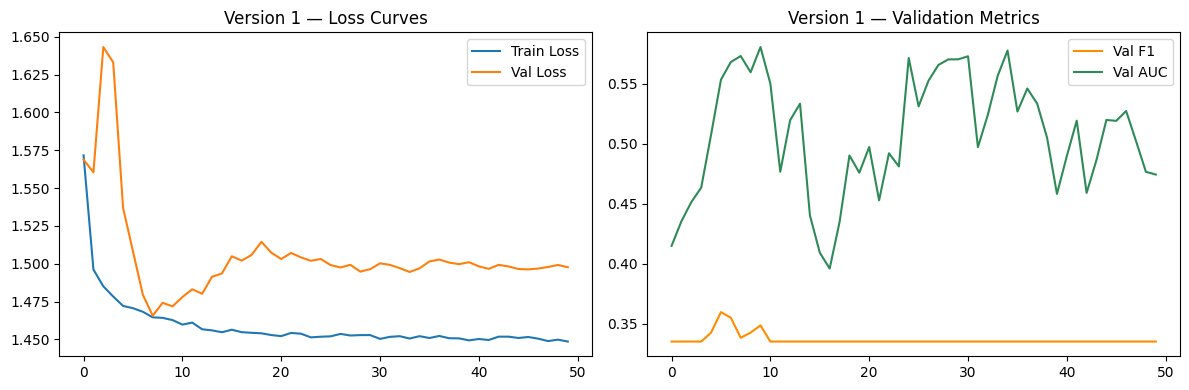

✅ Saved: gnn_full_features_checkpoint.pth


In [71]:
# ============================================================
# TRAIN VERSION 1 — FULL FEATURES
# ============================================================
print("="*70)
print("TRAINING VERSION 1 — FULL FEATURES")
print("="*70)

model_full = GCNRiskModel(in_channels=NUM_NODE_FEATURES, hidden_channels=32, dropout=0.3).to(device)
model_full, history_full, criterion_full = train_gnn(
    model_full,
    train_loader_full,
    val_loader_full,
    pos_weight_full,
    epochs=50,
    lr=1e-3,
    name='gnn_full'
)

val_metrics_full, _, _ = evaluate_model(model_full, val_loader_full, criterion=criterion_full)
print(f"\n✅ Best Validation Metrics (Full):")
for k, v in val_metrics_full.items():
    print(f"   {k}: {v:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history_full['train_loss'], label='Train Loss')
axes[0].plot(history_full['val_loss'], label='Val Loss')
axes[0].set_title('Version 1 — Loss Curves')
axes[0].legend()
axes[1].plot(history_full['val_f1'], label='Val F1', color='darkorange')
axes[1].plot(history_full['val_auc'], label='Val AUC', color='seagreen')
axes[1].set_title('Version 1 — Validation Metrics')
axes[1].legend()
plt.tight_layout()
plt.show()

torch.save(model_full.state_dict(), 'gnn_full_features_checkpoint.pth')
print("✅ Saved: gnn_full_features_checkpoint.pth")

## 15. Train GNN — Version 2: Feature Selection

For the reduced feature version, we use:
- **AE anomaly score:** from the trained reduced AE
- **VAE malicious probability & uncertainty:** from the saved reduced-feature VAE checkpoint

TRAINING VERSION 2 — FEATURE SELECTION
Starting training for 50 epochs...
  Epoch   1 — Train Loss: 1.6018 | Val Loss: 1.6112 | Val F1: 0.3350 (Thresh: 0.10) | Val AUC: 0.3024
  Epoch   5 — Train Loss: 1.4830 | Val Loss: 1.5917 | Val F1: 0.3350 (Thresh: 0.10) | Val AUC: 0.3411
  Epoch  10 — Train Loss: 1.4662 | Val Loss: 1.4414 | Val F1: 0.4389 (Thresh: 0.75) | Val AUC: 0.7070
  Epoch  15 — Train Loss: 1.4594 | Val Loss: 1.4337 | Val F1: 0.4691 (Thresh: 0.75) | Val AUC: 0.7494
  Epoch  20 — Train Loss: 1.4544 | Val Loss: 1.4085 | Val F1: 0.4467 (Thresh: 0.75) | Val AUC: 0.7109
  Epoch  25 — Train Loss: 1.4504 | Val Loss: 1.4581 | Val F1: 0.4265 (Thresh: 0.75) | Val AUC: 0.6942
  Epoch  30 — Train Loss: 1.4483 | Val Loss: 1.4482 | Val F1: 0.4265 (Thresh: 0.75) | Val AUC: 0.6721
  Epoch  35 — Train Loss: 1.4460 | Val Loss: 1.4335 | Val F1: 0.4265 (Thresh: 0.75) | Val AUC: 0.7120
  Epoch  40 — Train Loss: 1.4462 | Val Loss: 1.4653 | Val F1: 0.4265 (Thresh: 0.75) | Val AUC: 0.6588
  Epoch 

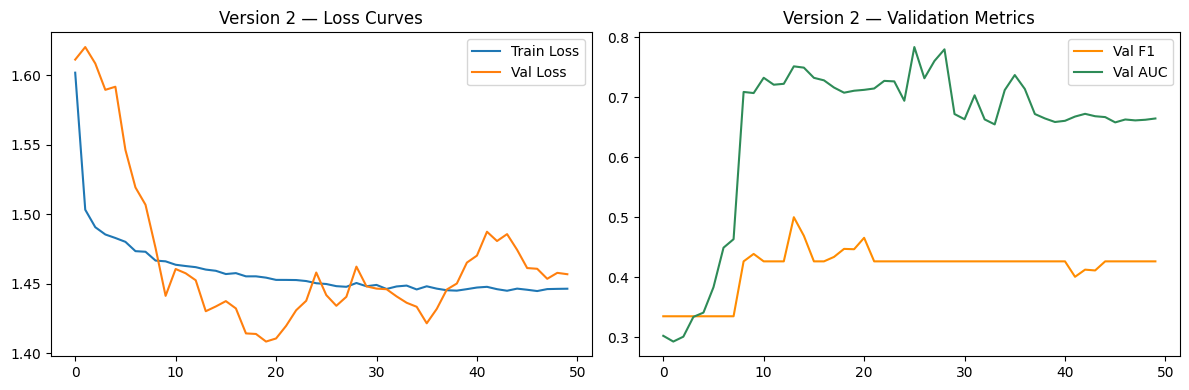

✅ Saved: gnn_feature_selection_checkpoint.pth


In [72]:
# ============================================================
# TRAIN VERSION 2 — FEATURE SELECTION
# ============================================================
print("="*70)
print("TRAINING VERSION 2 — FEATURE SELECTION")
print("="*70)

model_reduced = GCNRiskModel(in_channels=NUM_NODE_FEATURES, hidden_channels=32, dropout=0.3).to(device)
model_reduced, history_reduced, criterion_reduced = train_gnn(
    model_reduced,
    train_loader_reduced,
    val_loader_reduced,
    pos_weight_reduced,
    epochs=50,
    lr=1e-3,
    name='gnn_reduced'
)

val_metrics_reduced, _, _ = evaluate_model(model_reduced, val_loader_reduced, criterion=criterion_reduced)
print(f"\n✅ Best Validation Metrics (Reduced):")
for k, v in val_metrics_reduced.items():
    print(f"   {k}: {v:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history_reduced['train_loss'], label='Train Loss')
axes[0].plot(history_reduced['val_loss'], label='Val Loss')
axes[0].set_title('Version 2 — Loss Curves')
axes[0].legend()
axes[1].plot(history_reduced['val_f1'], label='Val F1', color='darkorange')
axes[1].plot(history_reduced['val_auc'], label='Val AUC', color='seagreen')
axes[1].set_title('Version 2 — Validation Metrics')
axes[1].legend()
plt.tight_layout()
plt.show()

torch.save(model_reduced.state_dict(), 'gnn_feature_selection_checkpoint.pth')
print("✅ Saved: gnn_feature_selection_checkpoint.pth")

## 16. Compute Node Risk Scores, Neighbor Risk Mean, and Global Graph Risk

In [73]:
# ============================================================
# INFERENCE: NODE RISKS, NEIGHBOR RISKS, GLOBAL GRAPH RISKS
# ============================================================

def compute_risk_outputs(model, data_list):
    """
    Run inference and compute:
      - node_risk_scores
      - neighbor_risk_mean
      - global_graph_risk = max(node_risk_scores)
    """
    model.eval()
    results = []

    with torch.no_grad():
        for data in data_list:
            data = data.to(device)
            logits = model(data.x, data.edge_index)
            risk_scores = torch.sigmoid(logits).cpu().numpy()
            global_risk = float(risk_scores.max())

            # Build neighbor list
            edge_idx = data.edge_index.cpu().numpy()
            neighbors = defaultdict(list)
            for src, dst in edge_idx.T:
                neighbors[int(src)].append(int(dst))

            for node_idx, machine in enumerate(data.machine_names):
                nbrs = neighbors.get(node_idx, [])
                if len(nbrs) > 0:
                    neighbor_risk_mean = float(np.mean(risk_scores[nbrs]))
                else:
                    neighbor_risk_mean = 0.0

                results.append({
                    'snapshot_idx': data.snapshot_idx,
                    'machine_name': machine,
                    'node_risk_score': float(risk_scores[node_idx]),
                    'neighbor_risk_mean': neighbor_risk_mean,
                    'global_graph_risk': global_risk,
                    'label': int(data.y[node_idx].item())
                })

    return pd.DataFrame(results)

# Compute for both versions on test sets
risk_results_full = compute_risk_outputs(model_full, test_full)
risk_results_reduced = compute_risk_outputs(model_reduced, test_reduced)

print("="*70)
print("RISK OUTPUTS — VERSION 1 (FULL)")
print("="*70)
print(risk_results_full.head().to_string(index=False))

print(f"\nHigh-risk snapshots (Full):")
high_risk_full = risk_results_full.groupby('snapshot_idx')['global_graph_risk'].max().sort_values(ascending=False).head(10)
print(high_risk_full.to_string())

print(f"\nHigh-risk nodes (Full):")
print(risk_results_full.sort_values('node_risk_score', ascending=False).head(10).to_string(index=False))

RISK OUTPUTS — VERSION 1 (FULL)
 snapshot_idx machine_name  node_risk_score  neighbor_risk_mean  global_graph_risk  label
        24841    machine-1         0.614498            0.632797           0.660494      0
        24841    machine-2         0.660494            0.614498           0.660494      0
        24841    machine-3         0.623398            0.614498           0.660494      0
        24841       ubuntu         0.614498            0.632797           0.660494      0
        24842    machine-1         0.614337            0.632650           0.660342      0

High-risk snapshots (Full):
snapshot_idx
28429    0.779694
28430    0.779631
28428    0.779588
28427    0.779520
28431    0.779509
28426    0.779461
28425    0.779398
28432    0.779364
28424    0.779351
28423    0.779282

High-risk nodes (Full):
 snapshot_idx machine_name  node_risk_score  neighbor_risk_mean  global_graph_risk  label
        28429    machine-2         0.779694            0.752798           0.779694      0
 

## 17. Visualize Graph Snapshots with Risk Scores

Representative snapshots:
  Low risk: 27377
  Medium risk: 25499
  High risk: 28429


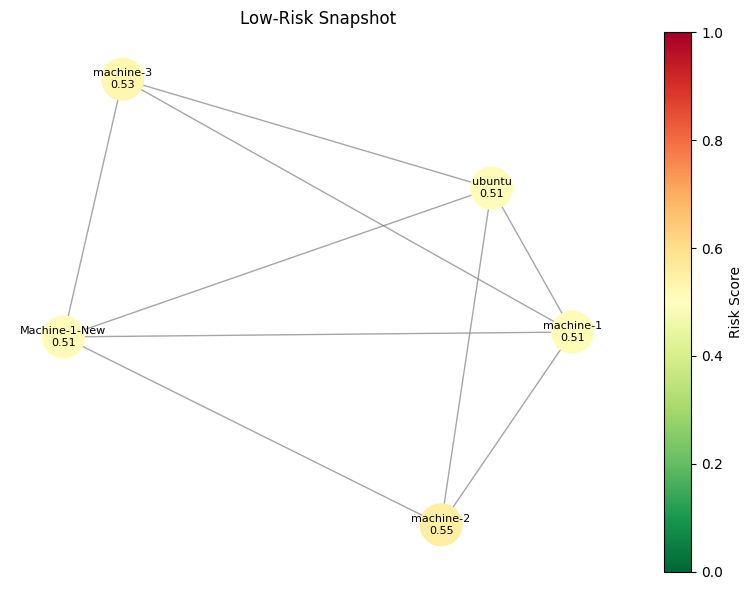

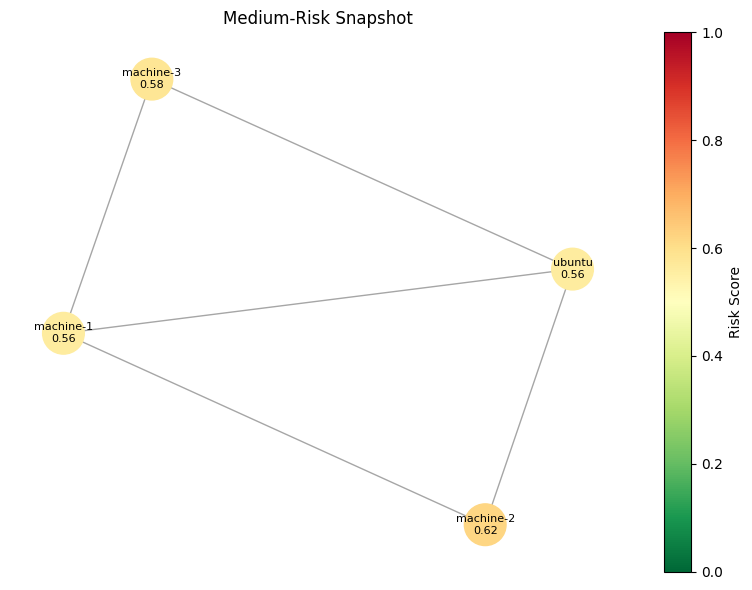

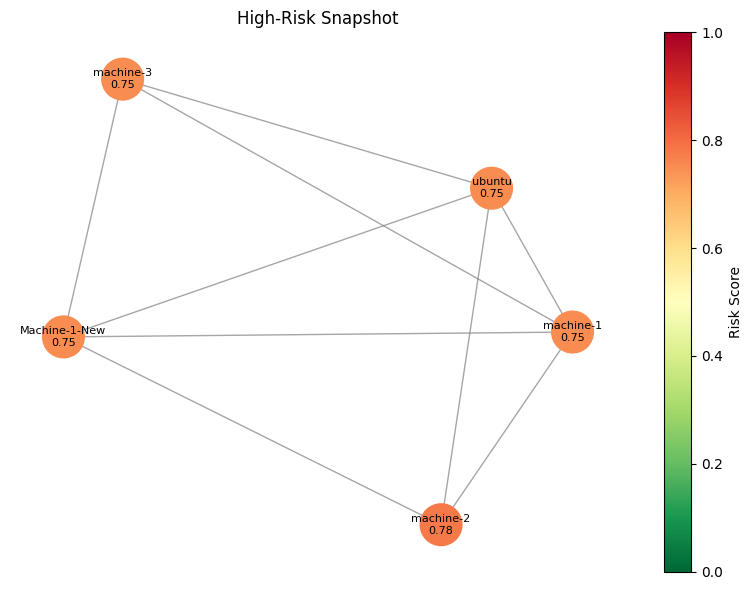

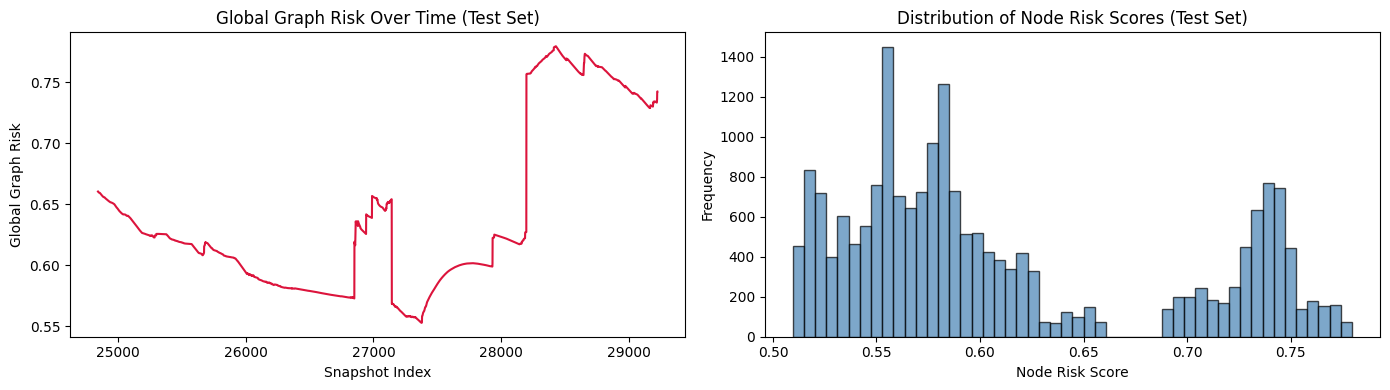

In [74]:
# ============================================================
# VISUALIZATIONS
# ============================================================

def plot_graph_with_risks(G, risk_df, snapshot_idx, title=''):
    """Plot a NetworkX graph with node colors based on risk scores."""
    snap_risks = risk_df[risk_df['snapshot_idx'] == snapshot_idx].set_index('machine_name')['node_risk_score']
    node_colors = [snap_risks.get(node, 0.0) for node in G.nodes()]
    labels = {n: f"{n}\n{snap_risks.get(n, 0.0):.2f}" for n in G.nodes()}

    fig, ax = plt.subplots(figsize=(8, 6))
    pos = nx.spring_layout(G, seed=42)
    nodes = nx.draw_networkx_nodes(G, pos, node_color=node_colors, cmap='RdYlGn_r',
                                   vmin=0, vmax=1, node_size=900, ax=ax)
    nx.draw_networkx_edges(G, pos, edge_color='gray', alpha=0.7, ax=ax)
    nx.draw_networkx_labels(G, pos, labels=labels, font_size=8, ax=ax)
    plt.colorbar(nodes, ax=ax, label='Risk Score')
    ax.set_title(title or f'Snapshot {snapshot_idx} — Graph Risk Visualization')
    ax.axis('off')
    plt.tight_layout()
    plt.show()

# Select representative snapshots based on global graph risk
snapshot_risk_full = risk_results_full.groupby('snapshot_idx')['global_graph_risk'].max().sort_values()
low_snap = snapshot_risk_full.index[0]
med_snap = snapshot_risk_full.index[len(snapshot_risk_full)//2]
high_snap = snapshot_risk_full.index[-1]

print(f"Representative snapshots:")
print(f"  Low risk: {low_snap}")
print(f"  Medium risk: {med_snap}")
print(f"  High risk: {high_snap}")

# Plot three representative graphs
plot_graph_with_risks(nx_graphs_full[low_snap], risk_results_full, low_snap, title='Low-Risk Snapshot')
plot_graph_with_risks(nx_graphs_full[med_snap], risk_results_full, med_snap, title='Medium-Risk Snapshot')
plot_graph_with_risks(nx_graphs_full[high_snap], risk_results_full, high_snap, title='High-Risk Snapshot')

# Timeline of global graph risk
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
global_risk_timeline = risk_results_full.groupby('snapshot_idx')['global_graph_risk'].max()
axes[0].plot(global_risk_timeline.index, global_risk_timeline.values, color='crimson')
axes[0].set_xlabel('Snapshot Index')
axes[0].set_ylabel('Global Graph Risk')
axes[0].set_title('Global Graph Risk Over Time (Test Set)')

axes[1].hist(risk_results_full['node_risk_score'], bins=50, color='steelblue', edgecolor='black', alpha=0.7)
axes[1].set_xlabel('Node Risk Score')
axes[1].set_ylabel('Frequency')
axes[1].set_title('Distribution of Node Risk Scores (Test Set)')

plt.tight_layout()
plt.show()

## 18. Evaluate and Compare Both GNN Versions

In [67]:
# ============================================================
# FINAL EVALUATION & COMPARISON
# ============================================================

def evaluate_on_test(model, loader, criterion):
    """Evaluate a trained model on the test set."""
    # use_best_threshold=True allows the model's threshold to adapt to lower probability ranges
    # which will increase the recall
    metrics, y_true, y_prob = evaluate_model(model, loader, criterion=criterion, use_best_threshold=True)
    return metrics, y_true, y_prob

# Test metrics
metrics_test_full, y_true_full, y_prob_full = evaluate_on_test(model_full, test_loader_full, criterion_full)
metrics_test_reduced, y_true_reduced, y_prob_reduced = evaluate_on_test(model_reduced, test_loader_reduced, criterion_reduced)

# Graph-level metric: snapshot flagged if global_graph_risk > threshold
def graph_level_metric(risk_df, threshold=0.5):
    grouped = risk_df.groupby('snapshot_idx').agg(
        global_graph_risk=('global_graph_risk', 'max'),
        has_malicious=('label', 'max')
    )
    grouped['flagged'] = (grouped['global_graph_risk'] > threshold).astype(int)
    acc = accuracy_score(grouped['has_malicious'], grouped['flagged'])
    prec = precision_score(grouped['has_malicious'], grouped['flagged'], zero_division=0)
    rec = recall_score(grouped['has_malicious'], grouped['flagged'], zero_division=0)
    f1 = f1_score(grouped['has_malicious'], grouped['flagged'], zero_division=0)
    return {'graph_accuracy': acc, 'graph_precision': prec, 'graph_recall': rec, 'graph_f1': f1}, grouped

# Apply optimal threshold found during node-level evaluation to the graph-level metrics
threshold_full = metrics_test_full.get('threshold', 0.5)
threshold_reduced = metrics_test_reduced.get('threshold', 0.5)

graph_metrics_full, graph_flags_full = graph_level_metric(risk_results_full, threshold=threshold_full)
graph_metrics_reduced, graph_flags_reduced = graph_level_metric(risk_results_reduced, threshold=threshold_reduced)

comparison = pd.DataFrame([
    {
        'Version': 'V1 - Full Features',
        'Node Accuracy': metrics_test_full['accuracy'],
        'Node Precision': metrics_test_full['precision'],
        'Node Recall': metrics_test_full['recall'],
        'Node F1': metrics_test_full['f1'],
        'Node AUC-ROC': metrics_test_full['auc_roc'],
        'Node AUC-PR': metrics_test_full['auc_pr'],
        'Graph Accuracy': graph_metrics_full['graph_accuracy'],
        'Graph Precision': graph_metrics_full['graph_precision'],
        'Graph Recall': graph_metrics_full['graph_recall'],
        'Graph F1': graph_metrics_full['graph_f1'],
        'Threshold used': threshold_full
    },
    {
        'Version': 'V2 - Feature Selection',
        'Node Accuracy': metrics_test_reduced['accuracy'],
        'Node Precision': metrics_test_reduced['precision'],
        'Node Recall': metrics_test_reduced['recall'],
        'Node F1': metrics_test_reduced['f1'],
        'Node AUC-ROC': metrics_test_reduced['auc_roc'],
        'Node AUC-PR': metrics_test_reduced['auc_pr'],
        'Graph Accuracy': graph_metrics_reduced['graph_accuracy'],
        'Graph Precision': graph_metrics_reduced['graph_precision'],
        'Graph Recall': graph_metrics_reduced['graph_recall'],
        'Graph F1': graph_metrics_reduced['graph_f1'],
        'Threshold used': threshold_reduced
    }
])

print('=' * 110)
print('FINAL GNN COMPARISON')
print('=' * 110)
display(comparison.round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

fpr_full, tpr_full, _ = roc_curve(y_true_full, y_prob_full)
fpr_red, tpr_red, _ = roc_curve(y_true_reduced, y_prob_reduced)
axes[0].plot(fpr_full, tpr_full, label=f'Full (AUC={metrics_test_full["auc_roc"]:.3f})', color='crimson')
axes[0].plot(fpr_red, tpr_red, label=f'Reduced (AUC={metrics_test_reduced["auc_roc"]:.3f})', color='steelblue')
axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.5)
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].set_title('ROC Curves — Node-Level Classification')
axes[0].legend()

prec_full, rec_full, _ = precision_recall_curve(y_true_full, y_prob_full)
prec_red, rec_red, _ = precision_recall_curve(y_true_reduced, y_prob_reduced)
axes[1].plot(rec_full, prec_full, label=f'Full (AP={metrics_test_full["auc_pr"]:.3f})', color='crimson')
axes[1].plot(rec_red, prec_red, label=f'Reduced (AP={metrics_test_reduced["auc_pr"]:.3f})', color='steelblue')
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].set_title('Precision-Recall Curves')
axes[1].legend()

plt.tight_layout()
plt.show()

print('\n' + '=' * 70)
print('SUMMARY OF FINDINGS')
print('=' * 70)
if metrics_test_full['auc_roc'] > metrics_test_reduced['auc_roc']:
    print('Version 1 (Full Features) performs better in node-level discrimination.')
else:
    print('Version 2 (Feature Selection) performs better in node-level discrimination.')

if graph_metrics_full['graph_f1'] > graph_metrics_reduced['graph_f1']:
    print('Version 1 also provides stronger graph-level attack snapshot detection.')
else:
    print('Version 2 provides stronger graph-level attack snapshot detection.')

print('\nPotential reasons:')
print('- Full features may capture richer anomaly context but include more noise.')
print('- Feature selection may reduce noise and improve generalization.')
print('- The reduced VAE is now loaded from a saved checkpoint instead of being assumed unavailable.')
print('- Snapshot generation and edge logic strongly influence propagation learning quality.')

TypeError: evaluate_model() got an unexpected keyword argument 'use_best_threshold'